# Solar DNI Forecasting, Part 1: Data Preparation

Downloads hourly NSRDB data for Tucson, AZ (1998-2024), checks quality, engineers features, and writes the train / validation / test splits used by `02_lstm_models.ipynb`:

* `data/train_solar_data.csv.gz`: 1998-2022
* `data/valid_solar_data.csv.gz`: 2023
* `data/test_solar_data.csv.gz`: 2024

The saved outputs below are from the original run. Re-running requires a free NREL API key (see `.env.example`).

**Team:** Shuyang Huang, Rick Jacoby, Jose Torres Berrios
**Course:** AI 570 - Deep Learning, Penn State (Spring 2026)

**Contributions in this notebook:**
* Data download, preprocessing, feature engineering and exploratory analysis: Rick Jacoby
* LSTM models 1-4, evaluation against the persistence baseline, and model comparisons: Shuyang Huang

### Problem Statement
This project forecasts hourly solar Direct Normal Irradiance (DNI) for Arizona using deep learning time-series models. DNI is important for solar power planning because it measures the amount of direct solar radiation available at a location.

The goal is to predict the next-hour DNI value from recent historical observations and selected weather or atmospheric predictors. The notebook compares univariate and multivariate LSTM models, and evaluates whether daytime-only target modeling or all-timestamp modeling performs better.

**Keywords:** solar forecasting, Direct Normal Irradiance, time series prediction, LSTM, deep learning, renewable energy.


### Data Collection
* **Source:** National Solar Radiation Database (NSRDB) solar/weather data prepared from project downloads and exported team-ready data files.
* **Files produced:** a processed model frame plus the train / validation / test splits in `data/` (`train_solar_data.csv.gz`, `valid_solar_data.csv.gz`, `test_solar_data.csv.gz`).
* **Short Description:** The dataset contains hourly solar irradiance and meteorological variables for Arizona, including DNI, GHI, DHI, clearsky irradiance values, temperature, humidity, pressure, wind speed, solar zenith angle, and aerosol optical depth.
* Note: the download cells read `NREL_API_KEY` and `NREL_EMAIL` from a `.env` file or environment variables.

**Keywords:** NSRDB, solar irradiance, Arizona, DNI, weather features, hourly time series.


In [77]:
# Libraries, Path, Config 

## note API guide says direct CSV downloads are for a single site and single year
### Source: https://developer.nrel.gov/docs/solar/nsrdb/guide

from __future__ import annotations

import json
import os
import sys
import time
from dataclasses import dataclass, asdict
from pathlib import Path

import pandas as pd
import requests
from dotenv import load_dotenv
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name.lower() == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
os.chdir(PROJECT_ROOT)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
load_dotenv(PROJECT_ROOT / ".env")

@dataclass
class RJV2DownloadConfig:
    location_name: str = "Tucson, AZ"
    location_slug: str = "tucson_az"
    latitude: float = 32.2226
    longitude: float = -110.9747
    start_year: int = 1998
    end_year: int = 2024
    interval: str = "60"
    leap_day: str = "true"
    utc: str = "false"  # local standard time for the data point, no DST adjustment per NREL docs
    api_key_env: str = "NREL_API_KEY"
    email_env: str = "NREL_EMAIL"
    endpoint: str = "https://developer.nrel.gov/api/nsrdb/v2/solar/nsrdb-GOES-aggregated-v4-0-0-download.csv"
    # BIG DEAL - leaving attr 'None' to get everything. To limit, we can set tuple of NSRDB attribute names.
    attributes: tuple[str, ...] | None = None

CFG = RJV2DownloadConfig()
RAW_DIR = PROJECT_ROOT / "data" / "raw" / "RJV2" / CFG.location_slug / "nsrdb"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed" / "RJV2" / CFG.location_slug
RAW_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

print(json.dumps(asdict(CFG), indent=2))
print("Project root:", PROJECT_ROOT)
print("CWD:", os.getcwd())
print("Repo on path:", str(PROJECT_ROOT) in sys.path)
print("Raw dir:", RAW_DIR)
print("Processed dir:", PROCESSED_DIR)


{
  "location_name": "Tucson, AZ",
  "location_slug": "tucson_az",
  "latitude": 32.2226,
  "longitude": -110.9747,
  "start_year": 1998,
  "end_year": 2024,
  "interval": "60",
  "leap_day": "true",
  "utc": "false",
  "api_key_env": "NREL_API_KEY",
  "email_env": "NREL_EMAIL",
  "endpoint": "https://developer.nrel.gov/api/nsrdb/v2/solar/nsrdb-GOES-aggregated-v4-0-0-download.csv",
  "attributes": null
}
Project root: <repo>
CWD: <repo>
Repo on path: True
Raw dir: <repo>/data/raw/RJV2/tucson_az/nsrdb
Processed dir: <repo>/data/processed/RJV2/tucson_az


In [78]:
# download helpers

## NREL NSRDB PSM3 docs: utc=false returns timestamps converted to the local time of the data point
## See https://developer.nrel.gov/docs/solar/nsrdb/psm3-download/

### NREL Python examples show CSV reads use skiprows=2 for data after metadata rows
### Ref https://developer.nrel.gov/docs/solar/nsrdb/python-examples/

def api_credentials(cfg: RJV2DownloadConfig) -> tuple[str, str]:
    api_key = os.getenv(cfg.api_key_env)
    email = os.getenv(cfg.email_env)
    if not api_key or not email:
        raise RuntimeError(f"Missing {cfg.api_key_env} or {cfg.email_env}. Add them to .env or your WSL shell environment.")
    return api_key, email

def raw_year_path(year: int) -> Path:
    return RAW_DIR / f"RJV2_{CFG.location_slug}_nsrdb_{year}_local.csv"

def download_year(year: int, cfg: RJV2DownloadConfig, force: bool = False) -> Path:
    out_path = raw_year_path(year)
    if out_path.exists() and out_path.stat().st_size > 10000 and not force:
        print(f"Skipping {year}; cached file exists: {out_path.name} ({out_path.stat().st_size:,} bytes)")
        return out_path

    api_key, email = api_credentials(cfg)
    params = {
        "api_key": api_key,
        "email": email,
        "wkt": f"POINT({cfg.longitude} {cfg.latitude})",
        "names": str(year),
        "interval": cfg.interval,
        "utc": cfg.utc,
        "leap_day": cfg.leap_day,
        "full_name": "Solar DNI Forecasting",
        "affiliation": "Penn State",
        "reason": "class project",
        "mailing_list": "false",
    }
    if cfg.attributes:
        params["attributes"] = ",".join(cfg.attributes)
    print(f"Requesting {cfg.location_name} {year} local_time utc={cfg.utc}...")
    with requests.get(cfg.endpoint, params=params, stream=True, timeout=180) as response:
        print("Status:", response.status_code)
        if response.status_code != 200:
            print(response.text[:1000])
            raise RuntimeError(f"Download failed for {year}")
        with open(out_path, "wb") as f:
            for chunk in response.iter_content(chunk_size=8192):
                if chunk:
                    f.write(chunk)
    print("Saved:", out_path, "bytes:", out_path.stat().st_size)
    return out_path

FORCE_DOWNLOAD = False
files = []
for year in range(CFG.start_year, CFG.end_year + 1):
    files.append(download_year(year, CFG, force=FORCE_DOWNLOAD))
    time.sleep(1.1)  # NREL guide documents a 1 request/second CSV download limit.

print("Downloaded/cached file count:", len(files))


Skipping 1998; cached file exists: RJV2_tucson_az_nsrdb_1998_local.csv (1,348,476 bytes)


Skipping 1999; cached file exists: RJV2_tucson_az_nsrdb_1999_local.csv (1,354,356 bytes)
Skipping 2000; cached file exists: RJV2_tucson_az_nsrdb_2000_local.csv (1,362,882 bytes)
Skipping 2001; cached file exists: RJV2_tucson_az_nsrdb_2001_local.csv (1,350,850 bytes)
Skipping 2002; cached file exists: RJV2_tucson_az_nsrdb_2002_local.csv (1,352,051 bytes)
Skipping 2003; cached file exists: RJV2_tucson_az_nsrdb_2003_local.csv (1,349,893 bytes)
Skipping 2004; cached file exists: RJV2_tucson_az_nsrdb_2004_local.csv (1,355,961 bytes)
Skipping 2005; cached file exists: RJV2_tucson_az_nsrdb_2005_local.csv (1,354,574 bytes)
Skipping 2006; cached file exists: RJV2_tucson_az_nsrdb_2006_local.csv (1,348,947 bytes)
Skipping 2007; cached file exists: RJV2_tucson_az_nsrdb_2007_local.csv (1,352,860 bytes)
Skipping 2008; cached file exists: RJV2_tucson_az_nsrdb_2008_local.csv (1,372,620 bytes)
Skipping 2009; cached file exists: RJV2_tucson_az_nsrdb_2009_local.csv (1,366,372 bytes)
Skipping 2010; cached

In [79]:
# Concat yearly downloads  

frames = []
metadata_rows = []
for path in sorted(RAW_DIR.glob(f"RJV2_{CFG.location_slug}_nsrdb_*_local.csv")):
    meta = pd.read_csv(path, nrows=1)
    meta["source_file"] = path.name
    metadata_rows.append(meta)
    year_df = pd.read_csv(path, skiprows=2)
    year_df["source_file"] = path.name
    frames.append(year_df)

if not frames:
    raise RuntimeError(f"No raw files found in {RAW_DIR}")

df_all = pd.concat(frames, ignore_index=True)
# NSRDB utc=false returns local standard time columns for the data point so timestamp directly from those columns
df_all["timestamp"] = pd.to_datetime(df_all[["Year", "Month", "Day", "Hour", "Minute"]])
df_all = df_all.sort_values("timestamp").drop_duplicates("timestamp").reset_index(drop=True)

metadata = pd.concat(metadata_rows, ignore_index=True)
parquet_path = PROCESSED_DIR / f"RJV2_{CFG.location_slug}_nsrdb_all_years_local.parquet"
csv_path = PROCESSED_DIR / f"RJV2_{CFG.location_slug}_nsrdb_all_years_local.csv"
metadata_path = PROCESSED_DIR / f"RJV2_{CFG.location_slug}_nsrdb_metadata.csv"
config_path = PROCESSED_DIR / f"RJV2_{CFG.location_slug}_download_config.json"

df_all.to_parquet(parquet_path, index=False)
df_all.to_csv(csv_path, index=False)
metadata.to_csv(metadata_path, index=False)
config_path.write_text(json.dumps(asdict(CFG), indent=2), encoding="utf-8")

print("Saved parquet:", parquet_path)
print("Saved csv:", csv_path)
print("Saved metadata:", metadata_path)
print("Shape:", df_all.shape)
print("Time range:", df_all["timestamp"].min(), "to", df_all["timestamp"].max())
display(df_all.head())
display(df_all.tail())


Saved parquet: <repo>/data/processed/RJV2/tucson_az/RJV2_tucson_az_nsrdb_all_years_local.parquet
Saved csv: <repo>/data/processed/RJV2/tucson_az/RJV2_tucson_az_nsrdb_all_years_local.csv
Saved metadata: <repo>/data/processed/RJV2/tucson_az/RJV2_tucson_az_nsrdb_metadata.csv
Shape: (236688, 32)
Time range: 1998-01-01 00:30:00 to 2024-12-31 23:30:00


,Year,Month,Day,Hour,Minute,Temperature,Alpha,Aerosol Optical Depth,Asymmetry,Clearsky DHI,...,SSA,Surface Albedo,Pressure,Precipitable Water,Wind Direction,Wind Speed,Global Horizontal UV Irradiance (280-400nm),Global Horizontal UV Irradiance (295-385nm),source_file,timestamp
0,1998,1,1,0,30,7.4,1.47,0.020,0.62,0,...,0.88,0.2,934,1.4,135,2.9,0.0,0.0,RJV2_tucson_az_nsrdb_1998_local.csv,1998-01-01 00:30:00
1,1998,1,1,1,30,7.0,1.47,0.020,0.62,0,...,0.88,0.2,934,1.4,133,3.0,0.0,0.0,RJV2_tucson_az_nsrdb_1998_local.csv,1998-01-01 01:30:00
2,1998,1,1,2,30,6.7,1.46,0.020,0.62,0,...,0.88,0.2,934,1.4,131,3.1,0.0,0.0,RJV2_tucson_az_nsrdb_1998_local.csv,1998-01-01 02:30:00
3,1998,1,1,3,30,6.4,1.46,0.019,0.62,0,...,0.88,0.2,933,1.4,130,3.1,0.0,0.0,RJV2_tucson_az_nsrdb_1998_local.csv,1998-01-01 03:30:00
4,1998,1,1,4,30,6.2,1.46,0.019,0.62,0,...,0.88,0.2,933,1.4,129,3.2,0.0,0.0,RJV2_tucson_az_nsrdb_1998_local.csv,1998-01-01 04:30:00


,Year,Month,Day,Hour,Minute,Temperature,Alpha,Aerosol Optical Depth,Asymmetry,Clearsky DHI,...,SSA,Surface Albedo,Pressure,Precipitable Water,Wind Direction,Wind Speed,Global Horizontal UV Irradiance (280-400nm),Global Horizontal UV Irradiance (295-385nm),source_file,timestamp
236683,2024,12,31,19,30,8.3,1.24,0.017,0.62,0,...,0.87,0.19,934,0.5,103,1.3,0.0,0.0,RJV2_tucson_az_nsrdb_2024_local.csv,2024-12-31 19:30:00
236684,2024,12,31,20,30,7.2,1.25,0.015,0.62,0,...,0.86,0.19,934,0.5,118,1.5,0.0,0.0,RJV2_tucson_az_nsrdb_2024_local.csv,2024-12-31 20:30:00
236685,2024,12,31,21,30,6.5,1.24,0.015,0.62,0,...,0.86,0.19,934,0.5,128,1.6,0.0,0.0,RJV2_tucson_az_nsrdb_2024_local.csv,2024-12-31 21:30:00
236686,2024,12,31,22,30,6.0,1.23,0.015,0.62,0,...,0.86,0.19,934,0.5,137,1.6,0.0,0.0,RJV2_tucson_az_nsrdb_2024_local.csv,2024-12-31 22:30:00
236687,2024,12,31,23,30,5.5,1.22,0.015,0.62,0,...,0.87,0.19,934,0.4,144,1.6,0.0,0.0,RJV2_tucson_az_nsrdb_2024_local.csv,2024-12-31 23:30:00


In [80]:
# initial inspect

print("Columns:", len(df_all.columns))
print(df_all.columns.tolist())
print("Duplicate timestamps:", df_all["timestamp"].duplicated().sum())
print("Missing values top 20:")
display(df_all.isna().sum().sort_values(ascending=False).head(20))

if "DNI" in df_all.columns:
    display(df_all["DNI"].describe(percentiles=[0.01, 0.05, 0.5, 0.95, 0.99]))
if "Solar Zenith Angle" in df_all.columns:
    sza_day = df_all["Solar Zenith Angle"] < 90
    print("SZA daylight rows:", int(sza_day.sum()), "of", len(df_all), "pct", round(float(sza_day.mean() * 100), 2))


Columns: 32
['Year', 'Month', 'Day', 'Hour', 'Minute', 'Temperature', 'Alpha', 'Aerosol Optical Depth', 'Asymmetry', 'Clearsky DHI', 'Clearsky DNI', 'Clearsky GHI', 'Cloud Fill Flag', 'Cloud Type', 'Dew Point', 'DHI', 'DNI', 'Fill Flag', 'GHI', 'Ozone', 'Relative Humidity', 'Solar Zenith Angle', 'SSA', 'Surface Albedo', 'Pressure', 'Precipitable Water', 'Wind Direction', 'Wind Speed', 'Global Horizontal UV Irradiance (280-400nm)', 'Global Horizontal UV Irradiance (295-385nm)', 'source_file', 'timestamp']
Duplicate timestamps: 0
Missing values top 20:


Year                     0
Month                    0
Day                      0
Hour                     0
Minute                   0
Temperature              0
Alpha                    0
Aerosol Optical Depth    0
Asymmetry                0
Clearsky DHI             0
Clearsky DNI             0
Clearsky GHI             0
Cloud Fill Flag          0
Cloud Type               0
Dew Point                0
DHI                      0
DNI                      0
Fill Flag                0
GHI                      0
Ozone                    0
dtype: int64

count    236688.000000
mean        311.923769
std         395.961343
min           0.000000
1%            0.000000
5%            0.000000
50%           0.000000
95%         971.000000
99%        1008.000000
max        1086.000000
Name: DNI, dtype: float64

SZA daylight rows: 120002 of 236688 pct 50.7


In [81]:
# Raw data dictionary
## Documents every downloaded NSRDB field before modeling transformations. Includes dtype, missingness, simple statistics, and source/definition links.
## Ref NREL NSRDB API documentation: https://developer.nrel.gov/docs/solar/nsrdb/

NSRDB_SOURCE_URL = "https://developer.nrel.gov/docs/solar/nsrdb/"
NSRDB_PSM3_URL = "https://developer.nrel.gov/docs/solar/nsrdb/psm3-download/"
CYCLICAL_FEATURE_URL = "https://scikit-learn.org/stable/auto_examples/applications/plot_cyclical_feature_engineering.html"
TIME_SERIES_FEATURE_URL = "https://otexts.com/fpp3/"

RAW_COLUMN_DEFINITIONS = {
    "Year": "Calendar year from the NSRDB local-standard-time record.",
    "Month": "Calendar month from the NSRDB local-standard-time record.",
    "Day": "Calendar day from the NSRDB local-standard-time record.",
    "Hour": "Hour of day from the NSRDB local-standard-time record.",
    "Minute": "Minute field from the NSRDB local-standard-time record.",
    "timestamp": "Datetime assembled from Year, Month, Day, Hour, and Minute; utc=false request returns local standard time for Tucson.",
    "Temperature": "Ambient air temperature at the site.",
    "Alpha": "Angstrom alpha aerosol parameter, describing wavelength dependence of aerosol optical depth.",
    "Aerosol Optical Depth": "Column aerosol optical depth; larger values generally indicate more atmospheric aerosol extinction.",
    "Asymmetry": "Aerosol scattering asymmetry factor used by NSRDB physical solar modeling.",
    "Clearsky DHI": "Diffuse horizontal irradiance expected under clear-sky conditions.",
    "Clearsky DNI": "Direct normal irradiance expected under clear-sky conditions.",
    "Clearsky GHI": "Global horizontal irradiance expected under clear-sky conditions.",
    "Cloud Fill Flag": "NSRDB quality/fill flag associated with cloud inputs.",
    "Cloud Type": "NSRDB categorical cloud type code; encoded separately in preprocessing rather than treated as ordinal.",
    "Dew Point": "Dew point temperature, a moisture-related atmospheric variable.",
    "DHI": "Diffuse horizontal irradiance observed/estimated for the all-sky condition.",
    "DNI": "Direct normal irradiance, the project target variable.",
    "Fill Flag": "NSRDB quality/fill flag for the data record.",
    "GHI": "Global horizontal irradiance observed/estimated for the all-sky condition.",
    "Ozone": "Column ozone amount used in atmospheric irradiance modeling.",
    "Relative Humidity": "Relative humidity near the surface.",
    "Solar Zenith Angle": "Angle between the sun and the local vertical; values below 90 degrees indicate sun above horizon.",
    "SSA": "Single scattering albedo, an aerosol optical property used in radiation transfer.",
    "Surface Albedo": "Fraction of incident shortwave radiation reflected by the surface.",
    "Pressure": "Atmospheric pressure at the site.",
    "Precipitable Water": "Total column water vapor; useful for atmospheric absorption and humidity regimes.",
    "Wind Direction": "Wind direction at the site.",
    "Wind Speed": "Wind speed at the site.",
    "Global Horizontal UV Irradiance (280-400nm)": "Global horizontal ultraviolet irradiance integrated over 280-400 nm.",
    "Global Horizontal UV Irradiance (295-385nm)": "Global horizontal ultraviolet irradiance integrated over 295-385 nm.",
    "source_file": "Local cached annual NSRDB CSV file used to build the combined dataset.",
}

def raw_column_definition(column: str) -> str:
    return RAW_COLUMN_DEFINITIONS.get(column, "NSRDB downloaded attribute; see NREL NSRDB field documentation.")

def raw_column_source(column: str) -> str:
    if column in {"timestamp", "source_file"}:
        return "Project-derived from NSRDB annual CSV files."
    if column == "Cloud Type":
        return NSRDB_PSM3_URL
    return NSRDB_SOURCE_URL


def raw_numeric_summary(series: pd.Series) -> dict:
    if pd.api.types.is_datetime64_any_dtype(series):
        clean = series.dropna()
        return {
            "min": clean.min() if len(clean) else None,
            "mean": clean.mean() if len(clean) else None,
            "max": clean.max() if len(clean) else None,
            "std": None,
            "p01": clean.quantile(0.01) if len(clean) else None,
            "p50": clean.quantile(0.50) if len(clean) else None,
            "p99": clean.quantile(0.99) if len(clean) else None,
        }
    numeric = pd.to_numeric(series, errors="coerce")
    if numeric.notna().sum() == 0:
        return {"min": None, "mean": None, "max": None, "std": None, "p01": None, "p50": None, "p99": None}
    q = numeric.quantile([0.01, 0.50, 0.99])
    return {
        "min": numeric.min(),
        "mean": numeric.mean(),
        "max": numeric.max(),
        "std": numeric.std(),
        "p01": q.loc[0.01],
        "p50": q.loc[0.50],
        "p99": q.loc[0.99],
    }

def infer_raw_role(column: str) -> str:
    if column == "timestamp":
        return "timestamp"
    if column == "DNI":
        return "target_candidate"
    if column in {"Year", "Month", "Day", "Hour", "Minute"}:
        return "raw_time_component"
    if column == "source_file":
        return "lineage"
    if column.startswith("Clearsky"):
        return "clear_sky_irradiance"
    if column in {"DHI", "GHI"}:
        return "irradiance_related"
    if column == "Cloud Type":
        return "categorical_cloud_type"
    return "raw_nsrdb_attribute"

def infer_raw_preprocessing_action(column: str) -> str:
    if column == "DNI":
        return "Target variable; clipped to physical bounds and used historically for sequence/lag features."
    if column in {"GHI", "DHI", "Clearsky GHI", "Clearsky DHI", "Global Horizontal UV Irradiance (280-400nm)", "Global Horizontal UV Irradiance (295-385nm)"}:
        return "Downloaded for inspection but excluded from model inputs to avoid same-time irradiance redundancy/leakage."
    if column == "Clearsky DNI":
        return "Retained as support for clear-sky baseline and lagged clear-sky engineered features; current value is not a direct model input."
    if column == "Cloud Type":
        return "Mapped to labels and optional one-hot/collapsed cloud-group features during preprocessing."
    if column in {"Year", "Month", "Day", "Hour", "Minute"}:
        return "Used to construct timestamp; cyclical time encodings are engineered later for modeling."
    if column == "timestamp":
        return "Used for chronological splitting, sequence framing, and time-based EDA."
    if column == "source_file":
        return "Lineage field retained for auditability, not a model input."
    return "Eligible exogenous/weather/solar-geometry field considered during preprocessing."

def infer_raw_modeling_status(column: str) -> str:
    if column == "DNI":
        return "target plus historical-only univariate sequence source; not allowed as current target-time multivariate input"
    if column in {"GHI", "DHI", "Clearsky GHI", "Clearsky DHI", "Global Horizontal UV Irradiance (280-400nm)", "Global Horizontal UV Irradiance (295-385nm)"}:
        return "excluded_from_training_current_irradiance_proxy"
    if column == "Clearsky DNI":
        return "support_only_current_value; lagged variants may train"
    if column == "Cloud Type":
        return "not_used_as_ordinal; optional encoded cloud features may train"
    if column in {"Year", "Month", "Day", "Hour", "Minute", "timestamp", "source_file"}:
        return "not_direct_model_input; used for time/indexing/lineage"
    return "candidate_exogenous_input_after_preprocessing"

raw_dictionary_rows = []
for column in df_all.columns:
    s = df_all[column]
    row = {
        "column": column,
        "dtype": str(s.dtype),
        "role": infer_raw_role(column),
        "preprocessing_action": infer_raw_preprocessing_action(column),
        "modeling_status_after_refactor": infer_raw_modeling_status(column),
        "definition": raw_column_definition(column),
        "source_url_or_note": raw_column_source(column),
        "sample_value": s.dropna().iloc[0] if s.notna().any() else None,
        "missing_count": int(s.isna().sum()),
        "missing_pct": float(s.isna().mean() * 100),
        "unique_values": int(s.nunique(dropna=True)),
    }
    row.update(raw_numeric_summary(s))
    raw_dictionary_rows.append(row)

raw_data_dictionary = pd.DataFrame(raw_dictionary_rows)
raw_dictionary_path = PROCESSED_DIR / f"RJV2_{CFG.location_slug}_raw_data_dictionary.csv"
raw_data_dictionary.to_csv(raw_dictionary_path, index=False)

print("Saved raw data dictionary:", raw_dictionary_path)
display(raw_data_dictionary)


Saved raw data dictionary: <repo>/data/processed/RJV2/tucson_az/RJV2_tucson_az_raw_data_dictionary.csv


,column,dtype,role,preprocessing_action,modeling_status_after_refactor,definition,source_url_or_note,sample_value,missing_count,missing_pct,unique_values,min,mean,max,std,p01,p50,p99
0,Year,int64,raw_time_component,Used to construct timestamp; cyclical time enc...,not_direct_model_input; used for time/indexing...,Calendar year from the NSRDB local-standard-ti...,https://developer.nrel.gov/docs/solar/nsrdb/,1998,0,0.0,27,1998,2011.00071,2024,7.789095,1998.0,2011.0,2024.0
1,Month,int64,raw_time_component,Used to construct timestamp; cyclical time enc...,not_direct_model_input; used for time/indexing...,Calendar month from the NSRDB local-standard-t...,https://developer.nrel.gov/docs/solar/nsrdb/,1,0,0.0,12,1,6.522815,12,3.448742,1.0,7.0,12.0
2,Day,int64,raw_time_component,Used to construct timestamp; cyclical time enc...,not_direct_model_input; used for time/indexing...,Calendar day from the NSRDB local-standard-tim...,https://developer.nrel.gov/docs/solar/nsrdb/,1,0,0.0,31,1,15.729974,31,8.800253,1.0,16.0,31.0
3,Hour,int64,raw_time_component,Used to construct timestamp; cyclical time enc...,not_direct_model_input; used for time/indexing...,Hour of day from the NSRDB local-standard-time...,https://developer.nrel.gov/docs/solar/nsrdb/,0,0,0.0,24,0,11.5,23,6.922201,0.0,11.5,23.0
4,Minute,int64,raw_time_component,Used to construct timestamp; cyclical time enc...,not_direct_model_input; used for time/indexing...,Minute field from the NSRDB local-standard-tim...,https://developer.nrel.gov/docs/solar/nsrdb/,30,0,0.0,1,30,30.0,30,0.000000,30.0,30.0,30.0
5,Temperature,float64,raw_nsrdb_attribute,Eligible exogenous/weather/solar-geometry fiel...,candidate_exogenous_input_after_preprocessing,Ambient air temperature at the site.,https://developer.nrel.gov/docs/solar/nsrdb/,7.4,0,0.0,516,-6.8,21.200804,46.3,9.778171,1.8,21.5,41.0
6,Alpha,float64,raw_nsrdb_attribute,Eligible exogenous/weather/solar-geometry fiel...,candidate_exogenous_input_after_preprocessing,"Angstrom alpha aerosol parameter, describing w...",https://developer.nrel.gov/docs/solar/nsrdb/,1.47,0,0.0,210,0.17,1.15971,2.26,0.290256,0.49,1.17,1.81
7,Aerosol Optical Depth,float64,raw_nsrdb_attribute,Eligible exogenous/weather/solar-geometry fiel...,candidate_exogenous_input_after_preprocessing,Column aerosol optical depth; larger values ge...,https://developer.nrel.gov/docs/solar/nsrdb/,0.02,0,0.0,626,0.01,0.073937,1.634,0.050238,0.018,0.064,0.246
8,Asymmetry,float64,raw_nsrdb_attribute,Eligible exogenous/weather/solar-geometry fiel...,candidate_exogenous_input_after_preprocessing,Aerosol scattering asymmetry factor used by NS...,https://developer.nrel.gov/docs/solar/nsrdb/,0.62,0,0.0,6,0.59,0.616612,0.64,0.013768,0.59,0.61,0.64
9,Clearsky DHI,int64,clear_sky_irradiance,Downloaded for inspection but excluded from mo...,excluded_from_training_current_irradiance_proxy,Diffuse horizontal irradiance expected under c...,https://developer.nrel.gov/docs/solar/nsrdb/,0,0,0.0,301,0,39.832649,350,46.199061,0.0,2.0,150.0


,hour,count,mean,median,max
0,0,9862,0.000000,0.0,0
1,1,9862,0.000000,0.0,0
2,2,9862,0.000000,0.0,0
3,3,9862,0.000000,0.0,0
4,4,9862,0.000000,0.0,0
5,5,9862,12.302981,0.0,260
6,6,9862,165.471000,1.0,717
7,7,9862,417.809775,524.0,882
8,8,9862,630.659603,763.0,963
9,9,9862,733.256439,870.0,1015


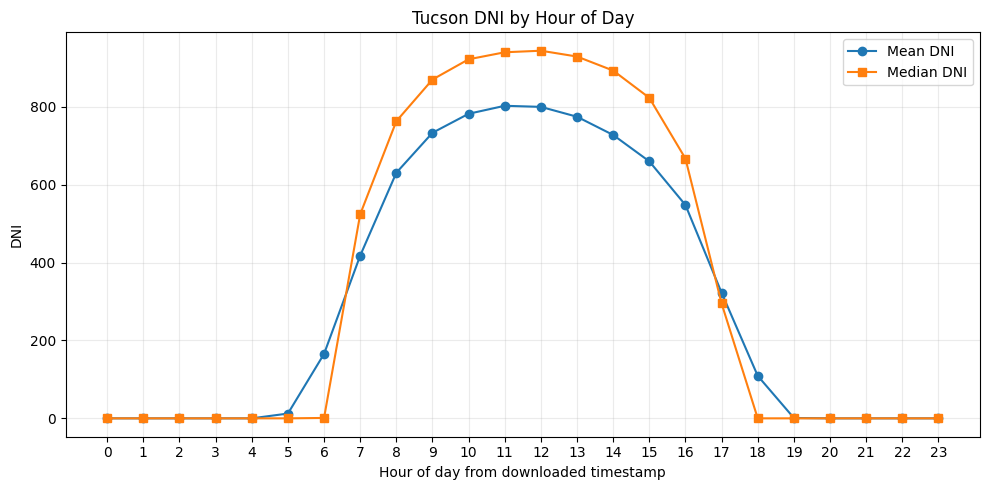

Peak mean DNI hour = 11:00
Looks consistent with local Tucson time. DNI peaks near midday


In [82]:
# Check DNI by hour of day (ensure we're getting local not Zulu)


import matplotlib.pyplot as plt

plot_df = df_all.copy()

plot_df["timestamp"] = pd.to_datetime(plot_df["timestamp"])
plot_df["hour"] = plot_df["timestamp"].dt.hour

dni_by_hour = (
    plot_df
    .groupby("hour")["DNI"]
    .agg(["count", "mean", "median", "max"])
    .reset_index()
)

display(dni_by_hour)

plt.figure(figsize=(10, 5))
plt.plot(dni_by_hour["hour"], dni_by_hour["mean"], marker="o", label="Mean DNI")
plt.plot(dni_by_hour["hour"], dni_by_hour["median"], marker="s", label="Median DNI")
plt.title("Tucson DNI by Hour of Day")
plt.xlabel("Hour of day from downloaded timestamp")
plt.ylabel("DNI")
plt.xticks(range(0, 24))
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()

peak_hour = int(dni_by_hour.loc[dni_by_hour["mean"].idxmax(), "hour"])
print(f"Peak mean DNI hour = {peak_hour}:00")

if 10 <= peak_hour <= 14:
    print("Looks consistent with local Tucson time. DNI peaks near midday")
else:
    print("Hmmm... DNI curve looks fishy... check timestamp handling")


### Required packages
Install the dependencies from `requirements.txt` (numpy, pandas, scipy, scikit-learn, matplotlib, seaborn, pyarrow, requests, python-dotenv, tensorflow).

Built-in Python modules such as `json`, `os`, `sys`, `math`, `time`, `re`, `dataclasses`, and `pathlib` do not need separate installation.

In [83]:
# import libraries
import os
import sys
from pathlib import Path
from IPython.display import display

import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pandas.plotting import autocorrelation_plot
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

In [84]:
# locate the project repository in a team-friendly way
import os
import sys
from pathlib import Path
from IPython.display import display

def is_repo_root(candidate: Path) -> bool:
    """
    Heuristic for the project root.
    We intentionally do NOT require generated folders like models/ or outputs/.
    """
    if not candidate.exists() or not candidate.is_dir():
        return False

    stable_markers = [
        candidate / "notebooks",
        candidate / "data",
    ]
    optional_files = [
        candidate / "requirements.txt",
        candidate / ".gitignore",
    ]

    has_core_dirs = all(path.exists() for path in stable_markers)
    has_any_file_marker = any(path.exists() for path in optional_files)
    has_git_marker = (candidate / ".git").exists()

    return has_core_dirs and (has_git_marker or has_any_file_marker)

def resolve_repo_root(start: Path | None = None) -> Path:
    candidates = []

    # 1. Explicit override
    env_root = os.environ.get("PROJECT_ROOT")
    if env_root:
        candidates.append(Path(env_root).expanduser())

    # 2. Current working directory and parents
    anchor = (start or Path.cwd()).resolve()
    candidates.extend([anchor, *anchor.parents])

    # 3. VS Code notebook path and parents
    notebook_path = globals().get("__vsc_ipynb_file__")
    if notebook_path:
        notebook_anchor = Path(notebook_path).resolve()
        candidates.extend([notebook_anchor.parent, *notebook_anchor.parent.parents])

    # 4. Jupyter fallback: current notebook may already be under repo/notebooks
    if "__file__" in globals():
        file_anchor = Path(__file__).resolve()
        candidates.extend([file_anchor.parent, *file_anchor.parent.parents])

    seen = set()
    for candidate in candidates:
        try:
            candidate = candidate.resolve()
        except FileNotFoundError:
            continue

        key = str(candidate).lower()
        if key in seen:
            continue
        seen.add(key)

        if is_repo_root(candidate):
            return candidate

    searched = "\n".join(f" - {str(c)}" for c in candidates[:15])
    raise FileNotFoundError(
        "Could not locate the project root.\n"
        "Try one of these:\n"
        "1. Open the notebook from inside the cloned repo\n"
        "2. Set PROJECT_ROOT to your local repo path\n"
        "3. Start VS Code/Jupyter with the repo as the working directory\n\n"
        f"Searched candidates:\n{searched}"
    )

repo_root = resolve_repo_root()
os.chdir(repo_root)

if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

print("cwd:", os.getcwd())
print("repo_root:", repo_root)
print("repo on path:", str(repo_root) in sys.path)


cwd: <repo>
repo_root: <repo>
repo on path: True


In [85]:
# notebook-wide run config and shared path helpers
from dataclasses import dataclass
import math
from sklearn.metrics import r2_score

######## HUGELY IMPORTANT CONFIG FLAGS FOR NOTEBOOK RUN BEHAVIOR #############
### can run smoke test for super light runs to ensure no bugs
### reload prior models for test/plots rather than retraining (if not reload or smoke test, allow long training too)
### Skip plots if just running smoke test

NOTEBOOK_SMOKE_TEST = False
NOTEBOOK_RELOAD_MODE = True
NOTEBOOK_ALLOW_LONG_TRAINING = True 
NOTEBOOK_SKIP_PRESENTATION_PLOTS = False 


@dataclass(frozen=True)
class NotebookRunConfig:
    smoke_test: bool = NOTEBOOK_SMOKE_TEST
    reload_mode: bool = NOTEBOOK_RELOAD_MODE
    allow_long_training: bool = NOTEBOOK_ALLOW_LONG_TRAINING
    skip_presentation_plots: bool = NOTEBOOK_SKIP_PRESENTATION_PLOTS


RUN_CONFIG = NotebookRunConfig()
print("Notebook run config:", RUN_CONFIG)

DATA_ROOT = repo_root / "data"
RAW_DATA_ROOT = DATA_ROOT / "raw"
PROCESSED_DATA_ROOT = DATA_ROOT / "processed"
MODEL_ROOT = repo_root / "models"


def first_existing_path(*candidates: Path) -> Path | None:
    for candidate in candidates:
        if candidate.exists():
            return candidate
    return None


def load_model_frame_from_repo(prefer_parquet: bool = True) -> pd.DataFrame:
    candidates = [
        PROCESSED_DATA_ROOT / "tucson_az" / "team_tucson_az_model_frame.parquet",
        PROCESSED_DATA_ROOT / "tucson_az" / "team_tucson_az_model_frame.csv",
        PROCESSED_DATA_ROOT / "RJV2" / "tucson_az" / "RJV2_tucson_az_model_frame.parquet",
        PROCESSED_DATA_ROOT / "RJV2" / "tucson_az" / "RJV2_tucson_az_model_frame.csv",
    ]
    if not prefer_parquet:
        candidates = sorted(candidates, key=lambda p: p.suffix == ".parquet")
    path = first_existing_path(*candidates)
    if path is None:
        raise FileNotFoundError(
            "No model-frame export found. Run the preprocessing section first so downstream cells can reuse the saved frame."
        )
    print("Loading model frame:", path)
    if path.suffix == ".parquet":
        df = pd.read_parquet(path)
    else:
        df = pd.read_csv(path)
    if "timestamp" in df.columns:
        df["timestamp"] = pd.to_datetime(df["timestamp"], errors="coerce")
    return df


def get_split_frames_from_feature_store() -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    if "feature_df" in globals() and isinstance(feature_df, pd.DataFrame) and len(feature_df):
        base = feature_df.copy()
        print("Using in-memory feature_df for split inspection.")
    else:
        base = load_model_frame_from_repo()
    if "split" not in base.columns:
        raise KeyError("Expected a 'split' column in the model frame / feature_df.")

    split_series = base["split"].astype(str).str.lower()
    train_df = base.loc[split_series == "train"].copy()
    validation_df = base.loc[split_series.isin(["validation", "valid"])].copy()
    test_df = base.loc[split_series == "test"].copy()
    return train_df, validation_df, test_df


def configured_epoch_count(default_epochs: int) -> int:
    return min(default_epochs, 2) if RUN_CONFIG.smoke_test else default_epochs


def should_skip_presentation_plots() -> bool:
    return RUN_CONFIG.smoke_test and RUN_CONFIG.skip_presentation_plots


def metric_bundle(
    y_true: np.ndarray,
    y_pred: np.ndarray,
    base_metrics: dict[str, float] | None = None,
) -> dict[str, float]:
    metrics = dict(base_metrics or {})
    y_true_arr = np.asarray(y_true, dtype=float).reshape(-1)
    y_pred_arr = np.asarray(y_pred, dtype=float).reshape(-1)
    if y_true_arr.size == 0:
        metrics.setdefault("R2", float("nan"))
        metrics.setdefault("nRMSE", float("nan"))
        return metrics

    metrics.setdefault("MAE", float(np.mean(np.abs(y_true_arr - y_pred_arr))))
    rmse = float(np.sqrt(np.mean((y_true_arr - y_pred_arr) ** 2)))
    metrics.setdefault("RMSE", rmse)
    denom = float(np.nanmean(np.abs(y_true_arr)))
    metrics.setdefault("nRMSE", float(rmse / denom * 100) if np.isfinite(denom) and denom > 1e-9 else float("nan"))
    try:
        metrics.setdefault("R2", float(r2_score(y_true_arr, y_pred_arr)))
    except Exception:
        metrics.setdefault("R2", float("nan"))

    if "MAPE" not in metrics:
        safe_denom = np.clip(np.abs(y_true_arr), 1e-3, None)
        metrics["MAPE"] = float(np.mean(np.abs((y_true_arr - y_pred_arr) / safe_denom)) * 100)
    return metrics

Notebook run config: NotebookRunConfig(smoke_test=False, reload_mode=True, allow_long_training=True, skip_presentation_plots=False)


### Data Preprocessing
This section covers the following:
* Loading the all-years Tucson dataset produced from download above.
* EDA to check for duplicates, missingness, clips DNI to a physically reasonable 0-1200 W/m^2 range; and creates an `is_daytime` indicator based on solar zenith angle, visualizations inspecting DNI over time, its distribution, sampled daily curves, and average hourly behavior.
* Apply time series safe (leakage proof) preprocessing, engineers features, creates train/validation/test splits, and writes team-friendly outputs for downstream modeling.


In [86]:
# Setup/ config 

# in/validation/test splits for time series should preserve chronological order to avoid look-ahead leakage.
# Ref Hyndman & Athanasopoulos, Forecasting: Principles and Practice, 3rd ed., Section 5.10

from __future__ import annotations

import json
import math
import os
import sys
from dataclasses import dataclass, asdict
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, MinMaxScaler

try:
    from statsmodels.stats.outliers_influence import variance_inflation_factor
    HAS_STATSMODELS = True
except Exception:
    HAS_STATSMODELS = False

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name.lower() == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
os.chdir(PROJECT_ROOT)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
print("Project root:", PROJECT_ROOT)
print("CWD:", os.getcwd())
print("Repo on path:", str(PROJECT_ROOT) in sys.path)

@dataclass
class RJV2PreprocessConfig:
    location_slug: str = "tucson_az"
    target_col: str = "DNI"
    timestamp_col: str = "timestamp"
    train_start: str = "1998-01-01 00:00:00"
    train_end: str = "2022-12-31 23:59:59"
    valid_start: str = "2023-01-01 00:00:00"
    valid_end: str = "2023-12-31 23:59:59"
    test_start: str = "2024-01-01 00:00:00"
    test_end: str = "2024-12-31 23:59:59"
    dni_min: float = 0.0
    dni_max: float = 1200.0
    sza_daylight_threshold: float = 90.0

CFG = RJV2PreprocessConfig()
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed" / "RJV2" / CFG.location_slug
OUTPUT_DIR = PROJECT_ROOT / "notebooks" / "outputs" / "team_preprocessing" / CFG.location_slug
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print(json.dumps(asdict(CFG), indent=2))
print("Processed dir:", PROCESSED_DIR)
print("Output dir:", OUTPUT_DIR)


Project root: <repo>
CWD: <repo>
Repo on path: True
{
  "location_slug": "tucson_az",
  "target_col": "DNI",
  "timestamp_col": "timestamp",
  "train_start": "1998-01-01 00:00:00",
  "train_end": "2022-12-31 23:59:59",
  "valid_start": "2023-01-01 00:00:00",
  "valid_end": "2023-12-31 23:59:59",
  "test_start": "2024-01-01 00:00:00",
  "test_end": "2024-12-31 23:59:59",
  "dni_min": 0.0,
  "dni_max": 1200.0,
  "sza_daylight_threshold": 90.0
}
Processed dir: <repo>/data/processed/RJV2/tucson_az
Output dir: <repo>/notebooks/outputs/team_preprocessing/tucson_az


In [87]:
# Load all-years Tucson local-time dataset

## Parquet preserves column types and is faster for repeated analytic reads than CSV
### Ref Apache Parquet documentation, https://parquet.apache.org/docs/

parquet_path = PROCESSED_DIR / f"RJV2_{CFG.location_slug}_nsrdb_all_years_local.parquet"
csv_path = PROCESSED_DIR / f"RJV2_{CFG.location_slug}_nsrdb_all_years_local.csv"
if parquet_path.exists():
    df = pd.read_parquet(parquet_path)
elif csv_path.exists():
    df = pd.read_csv(csv_path, parse_dates=[CFG.timestamp_col])
else:
    raise FileNotFoundError(f"Run RJV2_01 first. Missing {parquet_path} and {csv_path}")

df[CFG.timestamp_col] = pd.to_datetime(df[CFG.timestamp_col])
df = df.sort_values(CFG.timestamp_col).reset_index(drop=True)
print("Shape:", df.shape)
print("Time range:", df[CFG.timestamp_col].min(), "to", df[CFG.timestamp_col].max())
display(df.head())


Shape: (236688, 32)
Time range: 1998-01-01 00:30:00 to 2024-12-31 23:30:00


,Year,Month,Day,Hour,Minute,Temperature,Alpha,Aerosol Optical Depth,Asymmetry,Clearsky DHI,...,SSA,Surface Albedo,Pressure,Precipitable Water,Wind Direction,Wind Speed,Global Horizontal UV Irradiance (280-400nm),Global Horizontal UV Irradiance (295-385nm),source_file,timestamp
0,1998,1,1,0,30,7.4,1.47,0.020,0.62,0,...,0.88,0.2,934,1.4,135,2.9,0.0,0.0,RJV2_tucson_az_nsrdb_1998_local.csv,1998-01-01 00:30:00
1,1998,1,1,1,30,7.0,1.47,0.020,0.62,0,...,0.88,0.2,934,1.4,133,3.0,0.0,0.0,RJV2_tucson_az_nsrdb_1998_local.csv,1998-01-01 01:30:00
2,1998,1,1,2,30,6.7,1.46,0.020,0.62,0,...,0.88,0.2,934,1.4,131,3.1,0.0,0.0,RJV2_tucson_az_nsrdb_1998_local.csv,1998-01-01 02:30:00
3,1998,1,1,3,30,6.4,1.46,0.019,0.62,0,...,0.88,0.2,933,1.4,130,3.1,0.0,0.0,RJV2_tucson_az_nsrdb_1998_local.csv,1998-01-01 03:30:00
4,1998,1,1,4,30,6.2,1.46,0.019,0.62,0,...,0.88,0.2,933,1.4,129,3.2,0.0,0.0,RJV2_tucson_az_nsrdb_1998_local.csv,1998-01-01 04:30:00


In [88]:
# Quality checks e.g. dups/missing DNI beyond reasonable physical bounds

# Ref Professor feedback recommended clipping physically implausible DNI values instead of removing physical zeros

quality = {
    "n_rows": len(df),
    "duplicate_rows": int(df.duplicated().sum()),
    "duplicate_timestamps": int(df[CFG.timestamp_col].duplicated().sum()),
    "dni_below_min": int((pd.to_numeric(df[CFG.target_col], errors="coerce") < CFG.dni_min).sum()),
    "dni_above_max": int((pd.to_numeric(df[CFG.target_col], errors="coerce") > CFG.dni_max).sum()),
}
print(json.dumps(quality, indent=2))
missing = df.isna().sum().sort_values(ascending=False).reset_index()
missing.columns = ["column", "missing_count"]
missing["missing_pct"] = missing["missing_count"] / len(df)
display(missing.head(30))
missing.to_csv(OUTPUT_DIR / "RJV2_missing_values.csv", index=False)

df[CFG.target_col] = pd.to_numeric(df[CFG.target_col], errors="coerce").clip(CFG.dni_min, CFG.dni_max)


{
  "n_rows": 236688,
  "duplicate_rows": 0,
  "duplicate_timestamps": 0,
  "dni_below_min": 0,
  "dni_above_max": 0
}


,column,missing_count,missing_pct
0,Year,0,0.0
1,Month,0,0.0
2,Day,0,0.0
3,Hour,0,0.0
4,Minute,0,0.0
5,Temperature,0,0.0
6,Alpha,0,0.0
7,Aerosol Optical Depth,0,0.0
8,Asymmetry,0,0.0
9,Clearsky DHI,0,0.0


In [89]:
# Feature engineering

## Cyclical time encodings avoid artificial discontinuities at midnight/year-end, commonly represented with sine/cosine transforms.
### Lag and rolling features are standard supervised transformations for time series forecasting.
# Note interval is hours for lags/windows.
## Cloud type categorical handling via one-hot encoding and grouping.

### CACHE TOGGLES FOR SPEED!! 
USE_FEATURE_CACHE = True # True = if exists, don't rebuild
FORCE_REBUILD_FEATURE_CACHE = False # If True, ignore cache and rebuild even if cache file exists

LAGS = [1, 2, 3, 6, 12, 24, 48, 72, 168]
ROLL_WINDOWS = [3, 6, 24, 48, 168]

FEATURE_CACHE_TAG = "lookback72_groupedcloud_v1"
FEATURE_CACHE_PATH = OUTPUT_DIR / f"RJV2_feature_frame_{FEATURE_CACHE_TAG}.parquet"
FEATURE_SET_CACHE_PATH = OUTPUT_DIR / f"RJV2_feature_sets_{FEATURE_CACHE_TAG}.json"
CLOUD_LOOKUP_CACHE_PATH = OUTPUT_DIR / f"RJV2_cloud_type_lookup_{FEATURE_CACHE_TAG}.csv"

# Exogenous model inputs deliberately exclude current irradiance proxy fields (GHI/DHI/UV and current clear-sky irradiance)
# so the model is evaluated on weather/geometry/cloud context plus lagged DNI and lagged clear-sky context.
# This follows professor feedback about avoiding simultaneous irradiance redundancy/leakage.
BASE_EXOGENOUS_COLS = [
    "Temperature", "Alpha", "Aerosol Optical Depth", "Asymmetry",
    "Cloud Fill Flag", "Dew Point", "Fill Flag", "Ozone", "Relative Humidity", "Solar Zenith Angle",
    "SSA", "Surface Albedo", "Pressure", "Precipitable Water", "Wind Direction", "Wind Speed",
]
SUPPORT_COLS = ["Clearsky DNI"]  # retained for baseline construction and lagged clear-sky engineered features, not used directly in multivariate features

# Leakage policy: model features may use irradiance only when it is explicitly historical.
# Raw/current DNI is allowed only as the univariate sequence column; current GHI/DHI/UV/current clear-sky irradiance are never model inputs.
# If GHI/DHI features are added later, they must follow lag/rolling/difference naming such as ghi_lag_*, ghi_roll_*, or ghi_diff_*.
CURRENT_IRRADIANCE_BLOCKLIST = {
    "DNI", "GHI", "DHI", "Clearsky DNI", "Clearsky GHI", "Clearsky DHI",
    "Global Horizontal UV Irradiance (280-400nm)",
    "Global Horizontal UV Irradiance (295-385nm)",
}
HISTORICAL_IRRADIANCE_PREFIXES = (
    "dni_lag_", "dni_roll_", "dni_diff_",
    "ghi_lag_", "ghi_roll_", "ghi_diff_",
    "dhi_lag_", "dhi_roll_", "dhi_diff_",
    "clear_dni_lag_", "clear_index_lag_", "dni_vs_clear_",
)

def irradiance_policy_violations(feature_cols: list[str], *, allow_univariate_dni_sequence: bool = False) -> list[str]:
    violations = []
    for col in feature_cols:
        lower = col.lower()
        is_historical = lower.startswith(HISTORICAL_IRRADIANCE_PREFIXES)
        if col == CFG.target_col and allow_univariate_dni_sequence:
            continue
        if col in CURRENT_IRRADIANCE_BLOCKLIST:
            violations.append(col)
            continue
        mentions_ghi_dhi_uv = ("ghi" in lower) or ("dhi" in lower) or ("uv irradiance" in lower)
        mentions_current_clear = col.startswith("Clearsky ")
        if (mentions_ghi_dhi_uv or mentions_current_clear) and not is_historical:
            violations.append(col)
    return sorted(set(violations))

CLOUD_TYPE_LABELS = {
    -15: "N/A", 0: "Clear", 1: "Probably Clear", 2: "Fog", 3: "Water",
    4: "Super-Cooled Water", 5: "Mixed", 6: "Opaque Ice", 7: "Cirrus",
    8: "Overlapping", 9: "Overshooting", 10: "Unknown", 11: "Dust", 12: "Smoke",
}
CLOUD_TYPE_ORDER = list(CLOUD_TYPE_LABELS.values())

def cloud_type_slug(label: str) -> str:
    return pd.Series([label]).str.lower().str.replace("[^a-z0-9]+", "_", regex=True).str.strip("_").iloc[0]

ALL_CLOUD_TYPE_COLS = [f"cloud_type_{cloud_type_slug(label)}" for label in CLOUD_TYPE_ORDER]

CLOUD_TYPE_GROUPS = {
    "Clear": "Clear-like",
    "Probably Clear": "Clear-like",
    "Cirrus": "Thin high cloud",
    "Water": "Liquid/mixed cloud",
    "Super-Cooled Water": "Liquid/mixed cloud",
    "Mixed": "Liquid/mixed cloud",
    "Fog": "Thick/complex cloud",
    "Opaque Ice": "Thick/complex cloud",
    "Overlapping": "Thick/complex cloud",
    "Overshooting": "Thick/complex cloud",
    "N/A": "Rare/unknown",
    "Unknown": "Rare/unknown",
    "Dust": "Rare/unknown",
    "Smoke": "Rare/unknown",
}
CLOUD_GROUP_ORDER = ["Clear-like", "Thin high cloud", "Liquid/mixed cloud", "Thick/complex cloud", "Rare/unknown"]
ALL_CLOUD_GROUP_COLS = [f"cloud_group_{cloud_type_slug(label)}" for label in CLOUD_GROUP_ORDER]

cloud_type_lookup = pd.DataFrame({
    "cloud_type_code": list(CLOUD_TYPE_LABELS.keys()),
    "cloud_type_label": CLOUD_TYPE_ORDER,
    "cloud_type_one_hot_column": ALL_CLOUD_TYPE_COLS,
})
cloud_type_lookup["cloud_type_group"] = cloud_type_lookup["cloud_type_label"].map(CLOUD_TYPE_GROUPS).fillna("Rare/unknown")
cloud_type_lookup["cloud_group_one_hot_column"] = cloud_type_lookup["cloud_type_group"].map(
    lambda label: f"cloud_group_{cloud_type_slug(label)}"
)

if FORCE_REBUILD_FEATURE_CACHE or not CLOUD_LOOKUP_CACHE_PATH.exists():
    cloud_type_lookup.to_csv(CLOUD_LOOKUP_CACHE_PATH, index=False)

def add_features(input_df: pd.DataFrame) -> tuple[pd.DataFrame, dict[str, list[str]]]:
    out = input_df.copy().sort_values(CFG.timestamp_col).reset_index(drop=True)
    ts = out[CFG.timestamp_col]
    y = out[CFG.target_col].astype(float)
    clear = out["Clearsky DNI"].astype(float) if "Clearsky DNI" in out.columns else pd.Series(0.0, index=out.index)

    out["hour_sin"] = np.sin(2 * np.pi * ts.dt.hour / 24)
    out["hour_cos"] = np.cos(2 * np.pi * ts.dt.hour / 24)
    out["day_of_year"] = ts.dt.dayofyear
    out["day_of_year_sin"] = np.sin(2 * np.pi * out["day_of_year"] / 366)
    out["day_of_year_cos"] = np.cos(2 * np.pi * out["day_of_year"] / 366)
    out["month_sin"] = np.sin(2 * np.pi * ts.dt.month / 12)
    out["month_cos"] = np.cos(2 * np.pi * ts.dt.month / 12)
    out["is_sza_daylight"] = (out["Solar Zenith Angle"] < CFG.sza_daylight_threshold).astype(int) if "Solar Zenith Angle" in out.columns else (y > 0).astype(int)

    cloud_type_cols = []
    cloud_group_cols = []
    if "Cloud Type" in out.columns:
        cloud_codes = pd.to_numeric(out["Cloud Type"], errors="coerce").fillna(-15).astype(int)
        out["cloud_type_label"] = cloud_codes.map(CLOUD_TYPE_LABELS).fillna("Unknown")
        out["cloud_type_group"] = out["cloud_type_label"].map(CLOUD_TYPE_GROUPS).fillna("Rare/unknown")

        cloud_slugs = out["cloud_type_label"].map(cloud_type_slug)
        cloud_dummies = pd.get_dummies(cloud_slugs, prefix="cloud_type", dtype=int)
        for col in ALL_CLOUD_TYPE_COLS:
            if col not in cloud_dummies.columns:
                cloud_dummies[col] = 0
        cloud_dummies = cloud_dummies[ALL_CLOUD_TYPE_COLS]

        group_slugs = out["cloud_type_group"].map(cloud_type_slug)
        group_dummies = pd.get_dummies(group_slugs, prefix="cloud_group", dtype=int)
        for col in ALL_CLOUD_GROUP_COLS:
            if col not in group_dummies.columns:
                group_dummies[col] = 0
        group_dummies = group_dummies[ALL_CLOUD_GROUP_COLS]

        out = pd.concat([out, cloud_dummies, group_dummies], axis=1)
        cloud_type_cols = ALL_CLOUD_TYPE_COLS.copy()
        cloud_group_cols = ALL_CLOUD_GROUP_COLS.copy()
    else:
        out["cloud_type_label"] = "Unknown"
        out["cloud_type_group"] = "Rare/unknown"
        for col in ALL_CLOUD_TYPE_COLS:
            out[col] = 0
        for col in ALL_CLOUD_GROUP_COLS:
            out[col] = 0
        cloud_type_cols = ALL_CLOUD_TYPE_COLS.copy()
        cloud_group_cols = ALL_CLOUD_GROUP_COLS.copy()

    for lag in LAGS:
        out[f"dni_lag_{lag}"] = y.shift(lag)
        out[f"clear_dni_lag_{lag}"] = clear.shift(lag)
        out[f"clear_index_lag_{lag}"] = y.shift(lag) / (clear.shift(lag) + 1.0)

    for window in ROLL_WINDOWS:
        shifted = y.shift(1)
        out[f"dni_roll_mean_{window}"] = shifted.rolling(window, min_periods=max(2, window // 4)).mean()
        out[f"dni_roll_std_{window}"] = shifted.rolling(window, min_periods=max(2, window // 4)).std()
        out[f"dni_roll_max_{window}"] = shifted.rolling(window, min_periods=max(2, window // 4)).max()

    out["dni_diff_1"] = y.shift(1) - y.shift(2)
    out["dni_diff_24"] = y.shift(24) - y.shift(48)
    out["dni_vs_clear_lag_1"] = y.shift(1) - clear.shift(1)
    out["dni_vs_clear_lag_24"] = y.shift(24) - clear.shift(24)

    time_cols = ["hour_sin", "hour_cos", "day_of_year_sin", "day_of_year_cos", "month_sin", "month_cos"]
    univariate_cols = [CFG.target_col]
    dni_engineered_cols = [c for c in out.columns if c.startswith(("dni_lag_", "dni_roll_", "dni_diff_"))]
    exog_cols = [c for c in BASE_EXOGENOUS_COLS if c in out.columns]
    clear_engineered_cols = [c for c in out.columns if c.startswith(("clear_dni_lag_", "clear_index_lag_", "dni_vs_clear_"))]
    multivariate_cols = list(dict.fromkeys(time_cols + dni_engineered_cols + exog_cols + clear_engineered_cols))

    uni_violations = irradiance_policy_violations(univariate_cols, allow_univariate_dni_sequence=True)
    multi_violations = irradiance_policy_violations(multivariate_cols, allow_univariate_dni_sequence=False)
    if uni_violations or multi_violations:
        raise ValueError(
            "Current-time irradiance leakage detected. "
            f"Univariate violations={uni_violations}; multivariate violations={multi_violations}"
        )

    support_cols = [c for c in SUPPORT_COLS if c in out.columns]
    keep = list(dict.fromkeys(
        [CFG.timestamp_col, CFG.target_col, "is_sza_daylight", "day_of_year", "cloud_type_label", "cloud_type_group"]
        + support_cols
        + cloud_type_cols
        + cloud_group_cols
        + sorted(set(multivariate_cols))
    ))
    out = out[keep].replace([np.inf, -np.inf], np.nan).iloc[max(LAGS):].reset_index(drop=True)

    if out.columns.duplicated().any():
        dupes = out.columns[out.columns.duplicated()].tolist()
        raise ValueError(f"Duplicate columns after feature engineering: {dupes}")

    return out, {"univariate": univariate_cols, "multivariate": multivariate_cols}

def save_feature_cache(feature_df: pd.DataFrame, feature_sets: dict[str, list[str]]) -> None:
    feature_df.to_parquet(FEATURE_CACHE_PATH, index=False)
    with open(FEATURE_SET_CACHE_PATH, "w", encoding="utf-8") as f:
        json.dump(feature_sets, f, indent=2)

def load_feature_cache() -> tuple[pd.DataFrame, dict[str, list[str]]]:
    feature_df = pd.read_parquet(FEATURE_CACHE_PATH)
    with open(FEATURE_SET_CACHE_PATH, "r", encoding="utf-8") as f:
        feature_sets = json.load(f)
    return feature_df, feature_sets

feature_cache_exists = FEATURE_CACHE_PATH.exists() and FEATURE_SET_CACHE_PATH.exists()

if USE_FEATURE_CACHE and feature_cache_exists and not FORCE_REBUILD_FEATURE_CACHE:
    print(f"Loading engineered features from cache: {FEATURE_CACHE_PATH}")
    feature_df, feature_sets = load_feature_cache()
else:
    print("Building engineered features from source dataframe...")
    feature_df, feature_sets = add_features(df)
    save_feature_cache(feature_df, feature_sets)
    print(f"Saved engineered feature cache to: {FEATURE_CACHE_PATH}")

print("Feature frame:", feature_df.shape)
print("Feature counts:", {k: len(v) for k, v in feature_sets.items()})
print("Irradiance leakage audit:", {
    "univariate": irradiance_policy_violations(feature_sets["univariate"], allow_univariate_dni_sequence=True),
    "multivariate": irradiance_policy_violations(feature_sets["multivariate"], allow_univariate_dni_sequence=False),
})
display(feature_df.head())


Loading engineered features from cache: <repo>/notebooks/outputs/team_preprocessing/tucson_az/RJV2_feature_frame_lookback72_groupedcloud_v1.parquet
Feature frame: (236520, 94)
Feature counts: {'univariate': 1, 'multivariate': 68}
Irradiance leakage audit: {'univariate': [], 'multivariate': []}


,timestamp,DNI,is_sza_daylight,day_of_year,cloud_type_label,cloud_type_group,Clearsky DNI,cloud_type_n_a,cloud_type_clear,cloud_type_probably_clear,...,dni_roll_std_24,dni_roll_std_3,dni_roll_std_48,dni_roll_std_6,dni_vs_clear_lag_1,dni_vs_clear_lag_24,hour_cos,hour_sin,month_cos,month_sin
0,1998-01-08 00:30:00,0,0,8,Clear,Clear-like,0,0,1,0,...,452.862104,0.0,449.521146,0.0,0.0,0.0,1.000000,0.000000,0.866025,0.5
1,1998-01-08 01:30:00,0,0,8,Clear,Clear-like,0,0,1,0,...,452.862104,0.0,449.521146,0.0,0.0,0.0,0.965926,0.258819,0.866025,0.5
2,1998-01-08 02:30:00,0,0,8,Clear,Clear-like,0,0,1,0,...,452.862104,0.0,449.521146,0.0,0.0,0.0,0.866025,0.500000,0.866025,0.5
3,1998-01-08 03:30:00,0,0,8,Clear,Clear-like,0,0,1,0,...,452.862104,0.0,449.521146,0.0,0.0,0.0,0.707107,0.707107,0.866025,0.5
4,1998-01-08 04:30:00,0,0,8,Clear,Clear-like,0,0,1,0,...,452.862104,0.0,449.521146,0.0,0.0,0.0,0.500000,0.866025,0.866025,0.5


In [90]:
# Split train/test / val

def assign_split(ts: pd.Series) -> pd.Series:
    split = pd.Series("unused", index=ts.index, dtype="object")
    split[(ts >= pd.Timestamp(CFG.train_start)) & (ts <= pd.Timestamp(CFG.train_end))] = "train"
    split[(ts >= pd.Timestamp(CFG.valid_start)) & (ts <= pd.Timestamp(CFG.valid_end))] = "validation"
    split[(ts >= pd.Timestamp(CFG.test_start)) & (ts <= pd.Timestamp(CFG.test_end))] = "test"
    return split

feature_df["split"] = assign_split(feature_df[CFG.timestamp_col])
display(feature_df["split"].value_counts())


split
train         218976
test            8784
validation      8760
Name: count, dtype: int64

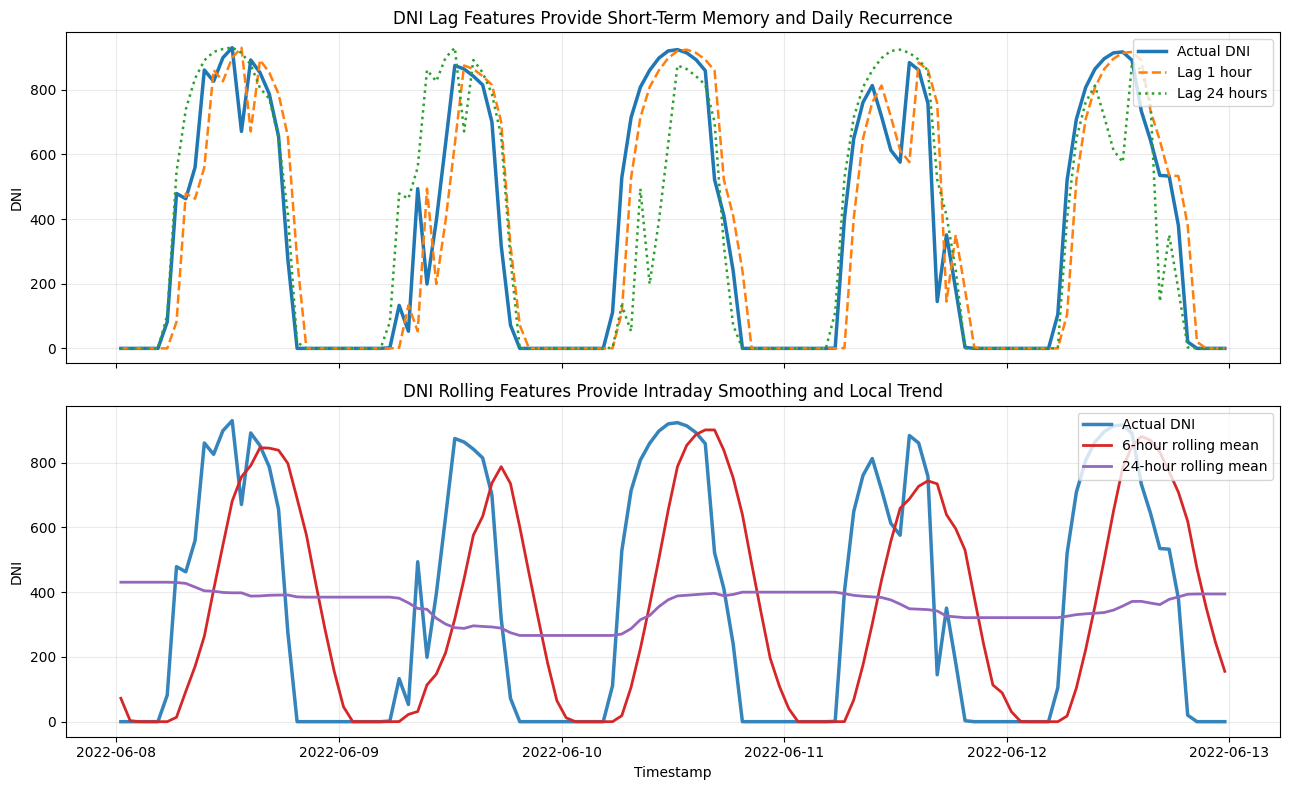

In [91]:
if should_skip_presentation_plots():
    print("Smoke test: skipping Plot for feature-engineering --- lagged DNI and rolling means to keep validation fast.")
else:
    # Plot for feature-engineering --- lagged DNI and rolling means
    ## REf Hyndman et al., 2026; Surakhi et al., 2021


    import matplotlib.pyplot as plt
    import pandas as pd

    plot_cols = [
        "timestamp",
        "DNI",
        "dni_lag_1",
        "dni_lag_24",
        "dni_roll_mean_6",
        "dni_roll_mean_24",
        "split",
    ]

    missing_cols = [c for c in plot_cols if c not in feature_df.columns]
    if missing_cols:
        raise KeyError(f"Missing required columns for lag plot: {missing_cols}")

    plot_df = feature_df[plot_cols].copy()
    plot_df["timestamp"] = pd.to_datetime(plot_df["timestamp"])

    # Shorter window makes the lag/rolling relationships easier see
    plot_window = plot_df[
        (plot_df["split"] == "train")
        & (plot_df["timestamp"] >= "2022-06-08")
        & (plot_df["timestamp"] < "2022-06-13")
    ].copy()

    fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)

    # plot 1 - lags
    axes[0].plot(plot_window["timestamp"], plot_window["DNI"], label="Actual DNI", linewidth=2.5, color="#1f77b4")
    axes[0].plot(plot_window["timestamp"], plot_window["dni_lag_1"], label="Lag 1 hour", linewidth=1.8, linestyle="--", color="#ff7f0e")
    axes[0].plot(plot_window["timestamp"], plot_window["dni_lag_24"], label="Lag 24 hours", linewidth=1.8, linestyle=":", color="#2ca02c")
    axes[0].set_title("DNI Lag Features Provide Short-Term Memory and Daily Recurrence")
    axes[0].set_ylabel("DNI")
    axes[0].grid(alpha=0.25)
    axes[0].legend(loc="upper right")

    # plot 2 - MA 
    axes[1].plot(plot_window["timestamp"], plot_window["DNI"], label="Actual DNI", linewidth=2.5, color="#1f77b4", alpha=0.9)
    axes[1].plot(plot_window["timestamp"], plot_window["dni_roll_mean_6"], label="6-hour rolling mean", linewidth=2.0, color="#d62728")
    axes[1].plot(plot_window["timestamp"], plot_window["dni_roll_mean_24"], label="24-hour rolling mean", linewidth=2.0, color="#9467bd")
    axes[1].set_title("DNI Rolling Features Provide Intraday Smoothing and Local Trend")
    axes[1].set_ylabel("DNI")
    axes[1].set_xlabel("Timestamp")
    axes[1].grid(alpha=0.25)
    axes[1].legend(loc="upper right")

    plt.tight_layout()
    plt.show()


,DNI_daylight_train
count,111034.000000
mean,613.839581
std,351.529880
min,0.000000
1%,0.000000
5%,0.000000
50%,753.000000
95%,990.000000
99%,1018.000000
max,1086.000000


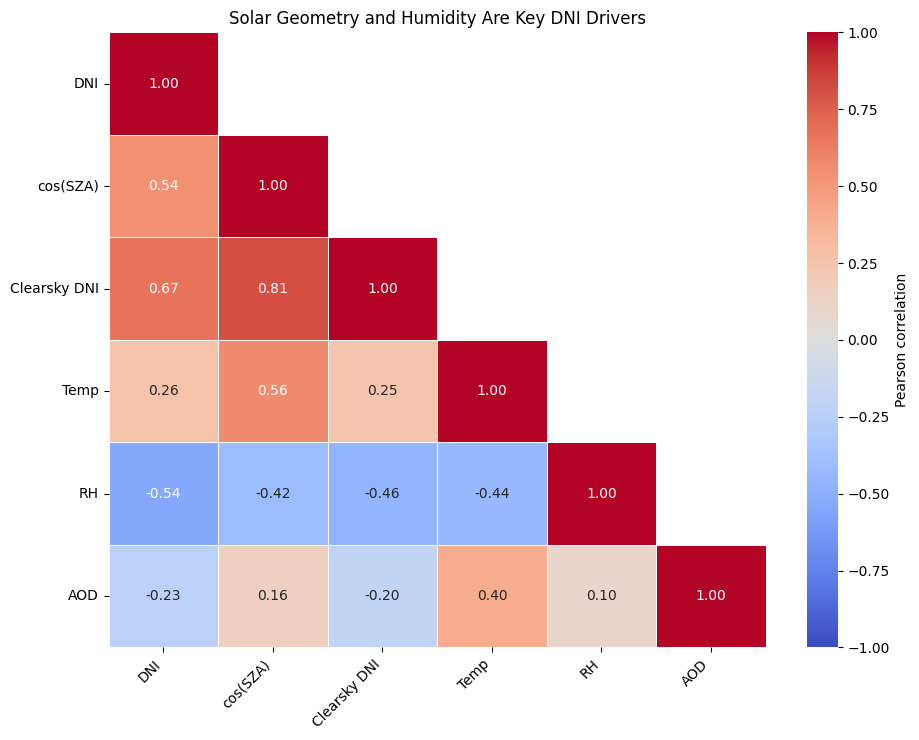

,feature,VIF
4,Pressure,65.273291
1,Clearsky DNI,57.300546
0,cos_sza,26.745670
2,Temperature,22.480542
3,Relative Humidity,5.766294
5,Wind Speed,5.454146
6,Aerosol Optical Depth,5.031047


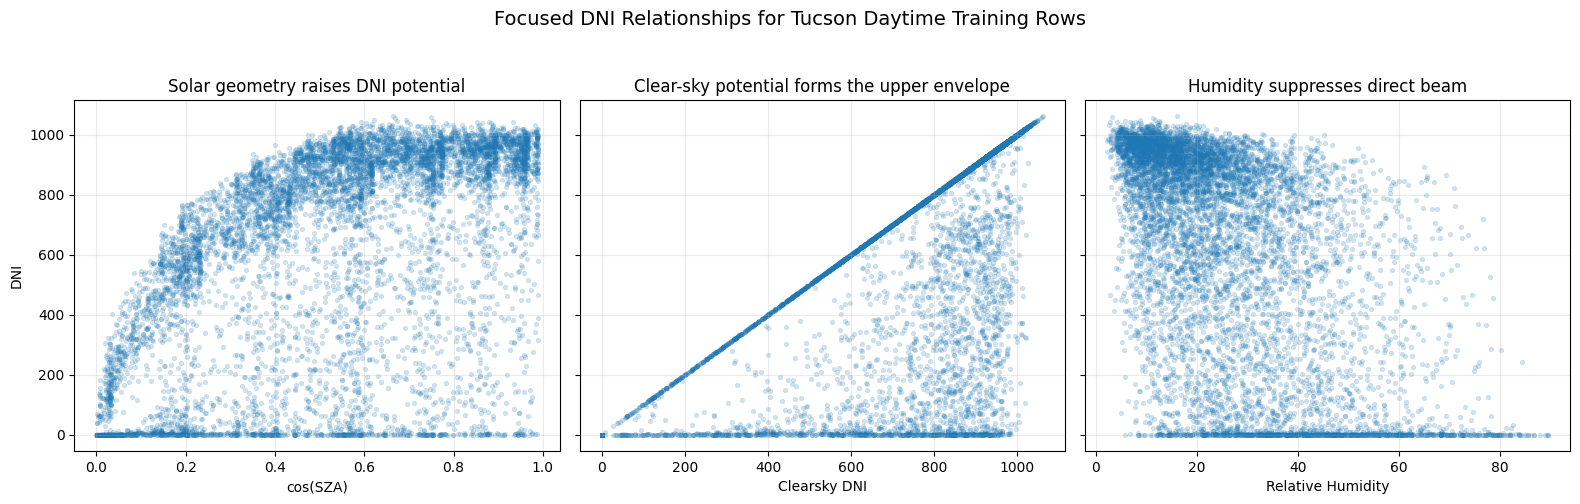

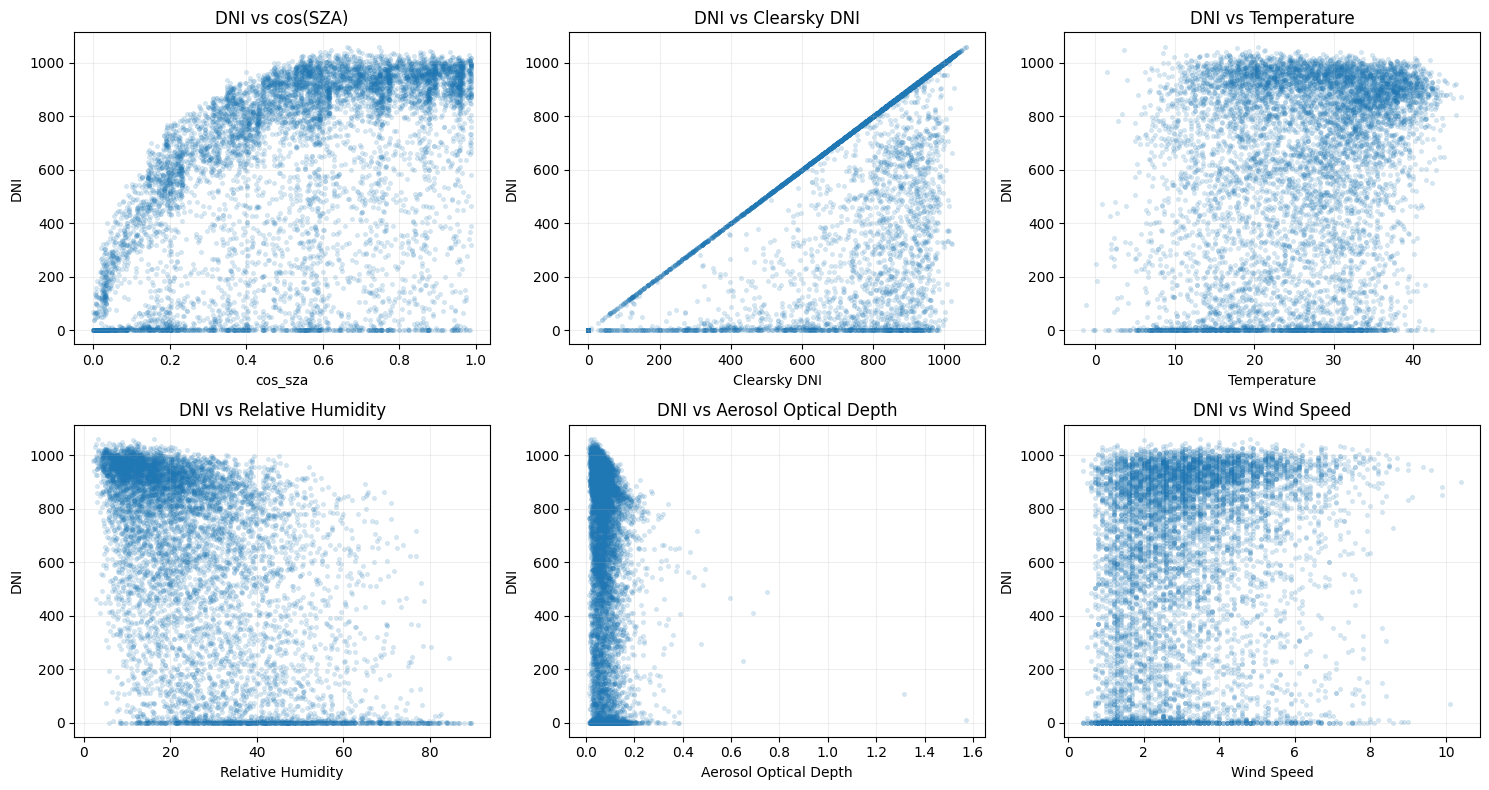

In [92]:
if should_skip_presentation_plots():
    print("Smoke test: skipping EDA: target summaries, correlations, VIF, and DNI-feature plots to keep validation fast.")
else:
    # EDA: target summaries, correlations, VIF, and DNI-feature plots
    ## Professor feedback requested stratified diagnostics and feature relationship checks

    train_day = feature_df[(feature_df["split"] == "train") & (feature_df["is_sza_daylight"] == 1)].copy()
    train_day["cos_sza"] = np.cos(np.radians(pd.to_numeric(train_day["Solar Zenith Angle"], errors="coerce")))
    summary = train_day[CFG.target_col].describe(percentiles=[0.01, 0.05, 0.5, 0.95, 0.99]).to_frame("DNI_daylight_train")
    display(summary)
    summary.to_csv(OUTPUT_DIR / "RJV2_dni_daylight_summary.csv")

    # Main deck heatmap: use cos(SZA) instead of raw SZA so solar geometry has the intuitive positive direction.
    # Keep this compact; VIF below still uses a broader diagnostic set.
    plot_rename = {
        CFG.target_col: "DNI",
        "cos_sza": "cos(SZA)",
        "Clearsky DNI": "Clearsky DNI",
        "Clearsky GHI": "Clearsky GHI",
        "Temperature": "Temp",
        "Relative Humidity": "RH",
        "Aerosol Optical Depth": "AOD",
    }
    heatmap_cols = [c for c in plot_rename if c in train_day.columns]
    corr = train_day[heatmap_cols].corr(numeric_only=True).rename(index=plot_rename, columns=plot_rename)
    corr.to_csv(OUTPUT_DIR / "RJV2_selected_correlation.csv")

    plt.figure(figsize=(9.5, 7.5))
    mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
    sns.heatmap(
        corr,
        mask=mask,
        annot=True,
        cmap="coolwarm",
        vmin=-1,
        vmax=1,
        center=0,
        fmt=".2f",
        linewidths=0.5,
        cbar_kws={"label": "Pearson correlation"},
    )
    plt.title("Solar Geometry and Humidity Are Key DNI Drivers")
    plt.xticks(rotation=45, ha="right")
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "RJV2_correlation_heatmap.png", dpi=180, bbox_inches="tight")
    plt.show()

    # Appendix diagnostic: VIF is useful for redundancy awareness, but not a strict exclusion rule for LSTM models.
    if HAS_STATSMODELS:
        vif_cols = [c for c in ["cos_sza", "Clearsky DNI", "Clearsky GHI", "Temperature", "Relative Humidity", "Pressure", "Wind Speed", "Aerosol Optical Depth"] if c in train_day.columns]
        X_vif = train_day[vif_cols].dropna().sample(min(10000, len(train_day[vif_cols].dropna())), random_state=42)
        vif_df = pd.DataFrame({"feature": vif_cols, "VIF": [variance_inflation_factor(X_vif[vif_cols].values, i) for i in range(len(vif_cols))]}).sort_values("VIF", ascending=False)
        display(vif_df)
        vif_df.to_csv(OUTPUT_DIR / "RJV2_vif_selected_features.csv", index=False)
    else:
        print("statsmodels not available; skipping VIF")

    # Focused scatter panels for the deck: upper-envelope physics, solar geometry, and humidity attenuation.
    scatter_cols = [c for c in ["cos_sza", "Clearsky DNI", "Relative Humidity"] if c in train_day.columns]
    scatter_labels = {
        "cos_sza": "cos(SZA)",
        "Clearsky DNI": "Clearsky DNI",
        "Relative Humidity": "Relative Humidity",
    }
    scatter_titles = {
        "cos_sza": "Solar geometry raises DNI potential",
        "Clearsky DNI": "Clear-sky potential forms the upper envelope",
        "Relative Humidity": "Humidity suppresses direct beam",
    }
    sample = train_day.sample(min(8000, len(train_day)), random_state=42)
    fig, axes = plt.subplots(1, len(scatter_cols), figsize=(5.3 * len(scatter_cols), 4.8), sharey=True)
    axes = np.atleast_1d(axes)
    for ax, col in zip(axes, scatter_cols):
        sns.scatterplot(data=sample, x=col, y=CFG.target_col, alpha=0.22, s=11, ax=ax, edgecolor=None)
        ax.set_title(scatter_titles[col])
        ax.set_xlabel(scatter_labels[col])
        ax.grid(alpha=0.25)
    axes[0].set_ylabel("DNI")
    fig.suptitle("Focused DNI Relationships for Tucson Daytime Training Rows", y=1.04, fontsize=14)
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "RJV2_dni_focused_relationships.png", dpi=180, bbox_inches="tight")
    plt.show()

    # Full exploratory scatter matrix kept for appendix/reference.
    plot_features = [c for c in ["cos_sza", "Clearsky DNI", "Temperature", "Relative Humidity", "Aerosol Optical Depth", "Wind Speed"] if c in train_day.columns]
    fig, axes = plt.subplots(math.ceil(len(plot_features) / 3), 3, figsize=(15, 4 * math.ceil(len(plot_features) / 3)))
    axes = np.array(axes).ravel()
    for ax, col in zip(axes, plot_features):
        sns.scatterplot(data=sample, x=col, y=CFG.target_col, alpha=0.18, s=10, ax=ax, edgecolor=None)
        ax.set_title(f"DNI vs {scatter_labels.get(col, col)}")
        ax.grid(alpha=0.2)
    for ax in axes[len(plot_features):]:
        ax.remove()
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "RJV2_dni_by_feature_scatter.png", dpi=160, bbox_inches="tight")
    plt.show()

In [93]:
if should_skip_presentation_plots():
    print("Smoke test: skipping daytime plotting frame: SZA daylight only to keep validation fast.")
else:
    # Daytime plotting frame: SZA daylight only
    ## Solar zenith angle below 90 degrees means the sun is above the horizon; this is cleaner than filtering on DNI > 0.
    ## Ref NREL solar position overview: https://www.nrel.gov/grid/solar-resource/solar-position.html

    required_cols = [CFG.timestamp_col, CFG.target_col, "Solar Zenith Angle"]
    missing_required = [c for c in required_cols if c not in feature_df.columns]
    if missing_required:
        raise KeyError(f"Missing required plotting columns: {missing_required}")

    train_daytime = feature_df[
        (feature_df["split"] == "train")
        & (pd.to_numeric(feature_df["Solar Zenith Angle"], errors="coerce") < CFG.sza_daylight_threshold)
    ].copy()

    train_daytime[CFG.timestamp_col] = pd.to_datetime(train_daytime[CFG.timestamp_col])
    train_daytime[CFG.target_col] = pd.to_numeric(train_daytime[CFG.target_col], errors="coerce")
    train_daytime["hour"] = train_daytime[CFG.timestamp_col].dt.hour
    train_daytime["month"] = train_daytime[CFG.timestamp_col].dt.month
    train_daytime["day_of_year"] = train_daytime[CFG.timestamp_col].dt.dayofyear

    season_map = {
        12: "Winter", 1: "Winter", 2: "Winter",
        3: "Spring", 4: "Spring", 5: "Spring",
        6: "Summer", 7: "Summer", 8: "Summer",
        9: "Fall", 10: "Fall", 11: "Fall",
    }
    season_order = ["Winter", "Spring", "Summer", "Fall"]
    train_daytime["season"] = pd.Categorical(train_daytime["month"].map(season_map), categories=season_order, ordered=True)

    # Presentation helpers: shoulder-season and monsoon context make Tucson's summer DNI dip easier to explain.
    # Approximate windows use meteorological seasons plus the common Arizona monsoon period of Jul-Sep.
    DOY_WINDOWS = {
        "Spring shoulder": (60, 151, "#d9f0d3"),
        "Monsoon / humid summer": (182, 273, "#dbe9f6"),
        "Fall shoulder": (274, 334, "#fee8c8"),
    }
    MONTH_LABELS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

    def add_doy_context(ax):
        ymax = ax.get_ylim()[1]
        for label, (start, end, color) in DOY_WINDOWS.items():
            ax.axvspan(start, end, color=color, alpha=0.45, zorder=0)
            ax.text((start + end) / 2, ymax * 0.985, label, ha="center", va="top", fontsize=9, color="#333333")
        ax.axvline(182, color="#2b6ca3", linestyle="--", linewidth=1, alpha=0.8)
        ax.axvline(273, color="#2b6ca3", linestyle="--", linewidth=1, alpha=0.8)

    def shade_monsoon_months(ax, categorical_month_axis=False):
        # For seaborn categorical month plots, month 7 is at x-position 6. For numeric month lines, month 7 is x=7.
        left, right = (5.5, 8.5) if categorical_month_axis else (6.5, 9.5)
        ax.axvspan(left, right, color="#dbe9f6", alpha=0.55, zorder=0, label="Jul-Sep monsoon window")

    def save_current_plot(filename: str):
        plt.tight_layout()
        plt.savefig(OUTPUT_DIR / filename, dpi=180, bbox_inches="tight")
        plt.show()

    print("Daytime train rows:", train_daytime.shape)
    print("Time range:", train_daytime[CFG.timestamp_col].min(), "to", train_daytime[CFG.timestamp_col].max())
    display(train_daytime[[CFG.timestamp_col, CFG.target_col, "Solar Zenith Angle", "hour", "month", "day_of_year", "season"]].head())

Daytime train rows: (111034, 98)
Time range: 1998-01-08 07:30:00 to 2022-12-31 16:30:00


,timestamp,DNI,Solar Zenith Angle,hour,month,day_of_year,season
7,1998-01-08 07:30:00,0,89.59,7,1,8,Winter
8,1998-01-08 08:30:00,1,79.07,8,1,8,Winter
9,1998-01-08 09:30:00,27,69.42,9,1,8,Winter
10,1998-01-08 10:30:00,34,61.55,10,1,8,Winter
11,1998-01-08 11:30:00,30,56.28,11,1,8,Winter


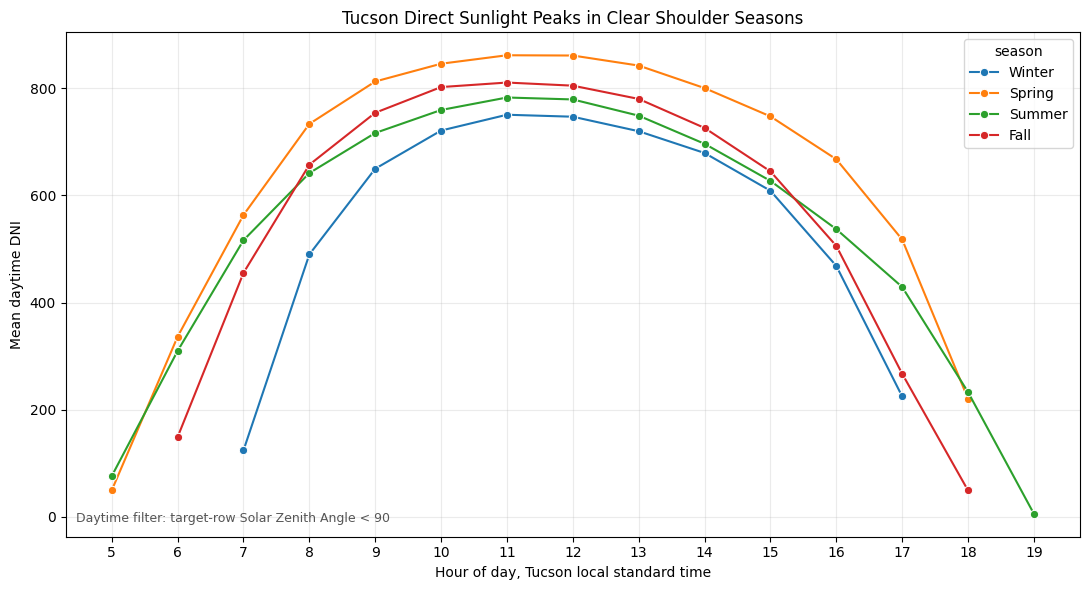

/tmp/ipykernel_922045/565966603.py:31: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(MONTH_LABELS)


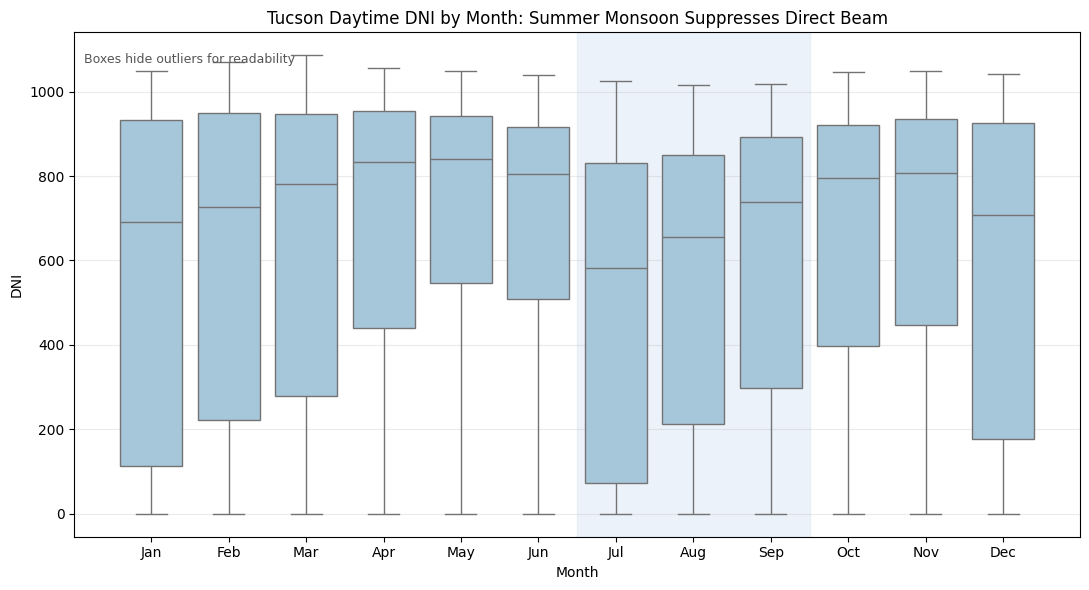

,month,mean,median,max,std,count
0,1,555.673343,692.0,1048,391.739552,8388
1,2,590.928792,726.0,1069,379.344333,7766
2,3,626.552748,781.0,1086,364.761292,9261
3,4,688.979795,834.0,1056,323.936368,9750
4,5,713.054220,840.0,1049,298.507593,10568
5,6,665.491238,804.0,1040,324.085039,10899
6,7,491.161653,582.0,1024,352.202508,10770
7,8,539.397419,655.0,1015,340.791353,10075
8,9,605.382413,739.0,1017,335.465836,9325
9,10,647.378142,796.0,1046,334.413748,8912


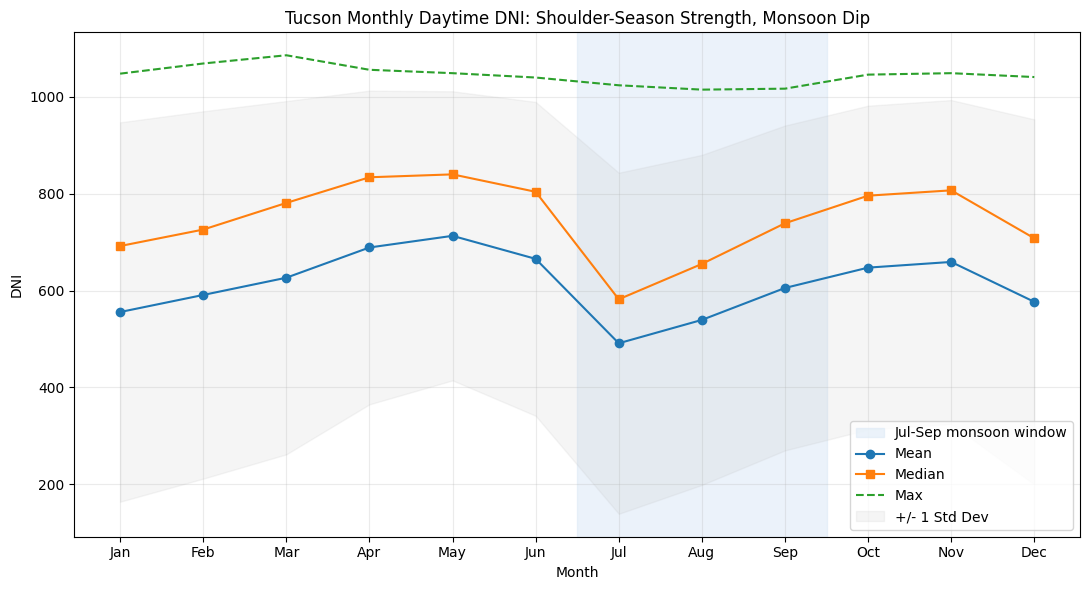

In [94]:
if should_skip_presentation_plots():
    print("Smoke test: skipping DNI by season and month to keep validation fast.")
else:
    # DNI by season and month
    ## Ref Professor feedback requested stratified diagnostics by time of day and season; these plots show train-period daytime DNI structure.

    season_hour_stats = (
        train_daytime
        .groupby(["season", "hour"], observed=True)[CFG.target_col]
        .agg(mean="mean", median="median", count="count")
        .reset_index()
    )
    season_hour_stats.to_csv(OUTPUT_DIR / "RJV2_dni_daytime_hour_by_season.csv", index=False)

    plt.figure(figsize=(11, 6))
    ax = sns.lineplot(data=season_hour_stats, x="hour", y="mean", hue="season", marker="o")
    ax.set_title("Tucson Direct Sunlight Peaks in Clear Shoulder Seasons")
    ax.set_xlabel("Hour of day, Tucson local standard time")
    ax.set_ylabel("Mean daytime DNI")
    ax.set_xticks(range(5, 20))
    ax.grid(alpha=0.25)
    ax.text(0.01, 0.03, "Daytime filter: target-row Solar Zenith Angle < 90", transform=ax.transAxes, fontsize=9, color="#555555")
    save_current_plot("RJV2_dni_daytime_hour_by_season.png")

    plt.figure(figsize=(11, 6))
    ax = sns.boxplot(data=train_daytime, x="month", y=CFG.target_col, color="#9ecae1", showfliers=False)
    shade_monsoon_months(ax, categorical_month_axis=True)
    ax.set_title("Tucson Daytime DNI by Month: Summer Monsoon Suppresses Direct Beam")
    ax.set_xlabel("Month")
    ax.set_ylabel("DNI")
    ax.set_xticklabels(MONTH_LABELS)
    ax.grid(axis="y", alpha=0.25)
    ax.text(0.01, 0.94, "Boxes hide outliers for readability", transform=ax.transAxes, fontsize=9, color="#555555")
    save_current_plot("RJV2_dni_daytime_month_boxplot.png")

    month_stats = (
        train_daytime
        .groupby("month")[CFG.target_col]
        .agg(mean="mean", median="median", max="max", std="std", count="count")
        .reset_index()
    )
    month_stats.to_csv(OUTPUT_DIR / "RJV2_dni_daytime_month_summary.csv", index=False)
    display(month_stats)

    plt.figure(figsize=(11, 6))
    ax = plt.gca()
    shade_monsoon_months(ax, categorical_month_axis=False)
    ax.plot(month_stats["month"], month_stats["mean"], marker="o", label="Mean")
    ax.plot(month_stats["month"], month_stats["median"], marker="s", label="Median")
    ax.plot(month_stats["month"], month_stats["max"], linestyle="--", label="Max")
    ax.fill_between(
        month_stats["month"],
        month_stats["mean"] - month_stats["std"],
        month_stats["mean"] + month_stats["std"],
        color="#bdbdbd",
        alpha=0.15,
        label="+/- 1 Std Dev",
    )
    ax.set_title("Tucson Monthly Daytime DNI: Shoulder-Season Strength, Monsoon Dip")
    ax.set_xlabel("Month")
    ax.set_ylabel("DNI")
    ax.set_xticks(range(1, 13))
    ax.set_xticklabels(MONTH_LABELS)
    ax.grid(alpha=0.25)
    ax.legend(loc="lower right")
    save_current_plot("RJV2_dni_daytime_month_summary.png")

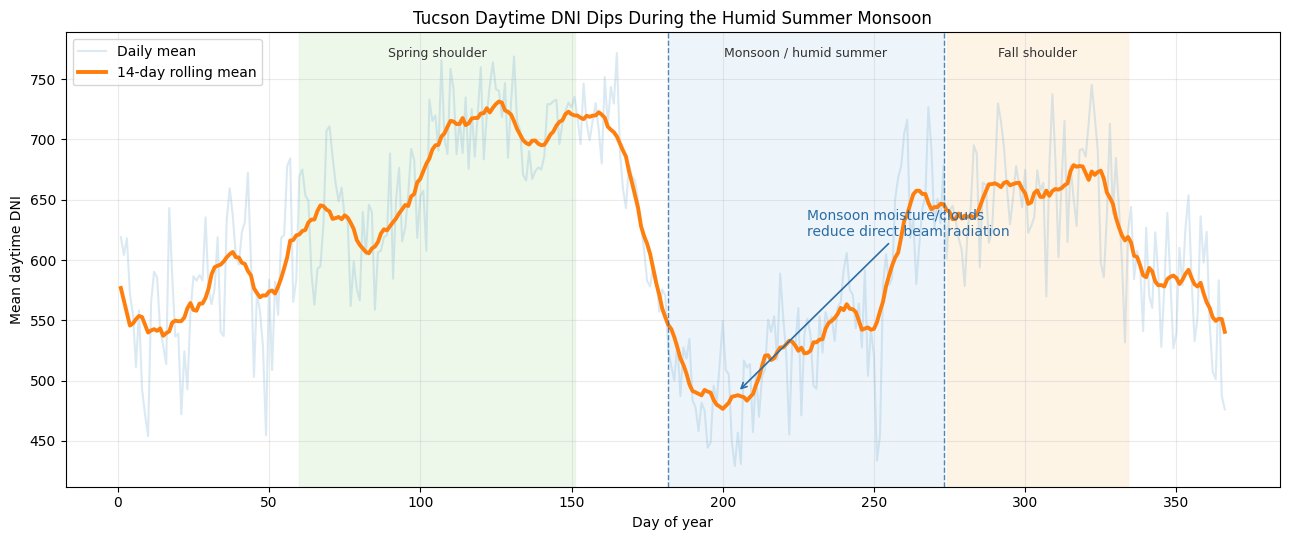

,hour,mean,median,max,std,count
0,5,68.051059,66.5,260,66.698381,1606
1,6,284.374336,296.0,717,220.528099,5268
2,7,416.407606,523.0,882,294.555852,9124
3,8,631.347874,763.0,963,297.024906,9124
4,9,733.760193,870.0,1015,297.945047,9124
5,10,782.460324,922.0,1066,297.568199,9124
6,11,801.689939,940.0,1076,295.275155,9124
7,12,798.298772,943.0,1086,303.428016,9124
8,13,773.079022,928.0,1081,311.408989,9124
9,14,725.739369,892.0,1063,318.066093,9124


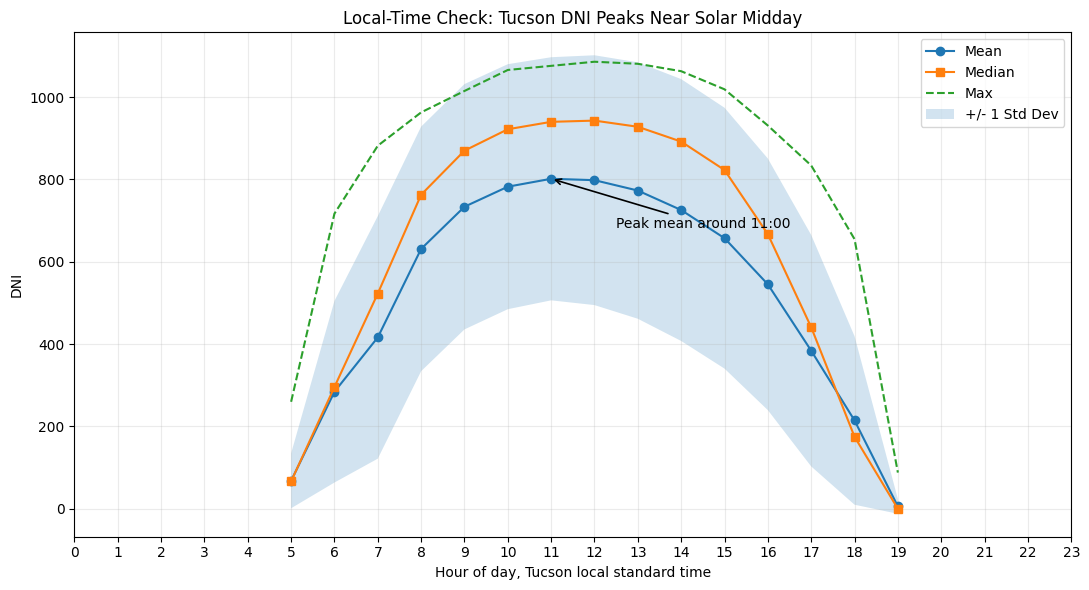

In [95]:
if should_skip_presentation_plots():
    print("Smoke test: skipping day-of-year and hour aggregation plots to keep validation fast.")
else:
    # DNI by day of year and hour
    ## Ref Time-of-year and hour-of-day aggregation helps separate seasonal solar geometry from weather noise.

    doy_stats = (
        train_daytime
        .groupby("day_of_year")[CFG.target_col]
        .agg(mean="mean", median="median", std="std", count="count")
        .reset_index()
    )
    doy_stats["mean_14d"] = doy_stats["mean"].rolling(14, center=True, min_periods=3).mean()
    doy_stats.to_csv(OUTPUT_DIR / "RJV2_dni_daytime_day_of_year_summary.csv", index=False)

    plt.figure(figsize=(13, 5.5))
    ax = plt.gca()
    ax.plot(doy_stats["day_of_year"], doy_stats["mean"], alpha=0.28, label="Daily mean", color="#7fb3d5")
    ax.plot(doy_stats["day_of_year"], doy_stats["mean_14d"], linewidth=2.8, label="14-day rolling mean", color="#ff7f0e")
    ax.set_title("Tucson Daytime DNI Dips During the Humid Summer Monsoon")
    ax.set_xlabel("Day of year")
    ax.set_ylabel("Mean daytime DNI")
    ax.grid(alpha=0.25)
    add_doy_context(ax)
    ax.annotate(
        "Monsoon moisture/clouds\nreduce direct beam radiation",
        xy=(205, doy_stats.loc[doy_stats["day_of_year"].between(195, 215), "mean_14d"].mean()),
        xytext=(228, 620),
        arrowprops={"arrowstyle": "->", "color": "#2b6ca3", "lw": 1.2},
        fontsize=10,
        color="#2b6ca3",
    )
    ax.legend(loc="upper left")
    save_current_plot("RJV2_dni_daytime_day_of_year.png")

    hour_stats = (
        train_daytime
        .groupby("hour")[CFG.target_col]
        .agg(mean="mean", median="median", max="max", std="std", count="count")
        .reset_index()
    )
    hour_stats.to_csv(OUTPUT_DIR / "RJV2_dni_daytime_hour_summary.csv", index=False)
    display(hour_stats)

    plt.figure(figsize=(11, 6))
    ax = plt.gca()
    ax.plot(hour_stats["hour"], hour_stats["mean"], marker="o", label="Mean")
    ax.plot(hour_stats["hour"], hour_stats["median"], marker="s", label="Median")
    ax.plot(hour_stats["hour"], hour_stats["max"], linestyle="--", label="Max")
    ax.fill_between(
        hour_stats["hour"],
        hour_stats["mean"] - hour_stats["std"],
        hour_stats["mean"] + hour_stats["std"],
        alpha=0.2,
        label="+/- 1 Std Dev",
    )
    ax.set_title("Local-Time Check: Tucson DNI Peaks Near Solar Midday")
    ax.set_xlabel("Hour of day, Tucson local standard time")
    ax.set_ylabel("DNI")
    ax.set_xticks(range(0, 24))
    ax.grid(alpha=0.25)
    ax.legend(loc="best")
    peak_hour = int(hour_stats.loc[hour_stats["mean"].idxmax(), "hour"])
    ax.annotate(
        f"Peak mean around {peak_hour}:00",
        xy=(peak_hour, hour_stats["mean"].max()),
        xytext=(peak_hour + 1.5, hour_stats["mean"].max() - 120),
        arrowprops={"arrowstyle": "->", "lw": 1.2},
        fontsize=10,
    )
    save_current_plot("RJV2_dni_daytime_hour_summary.png")

/tmp/ipykernel_922045/3323764820.py:14: FutureWarning: Support for axis=1 in DataFrame.rolling is deprecated and will be removed in a future version. Use obj.T.rolling(...) instead
  surface_pivot = surface_pivot.rolling(window=7, axis=1, min_periods=3).mean()


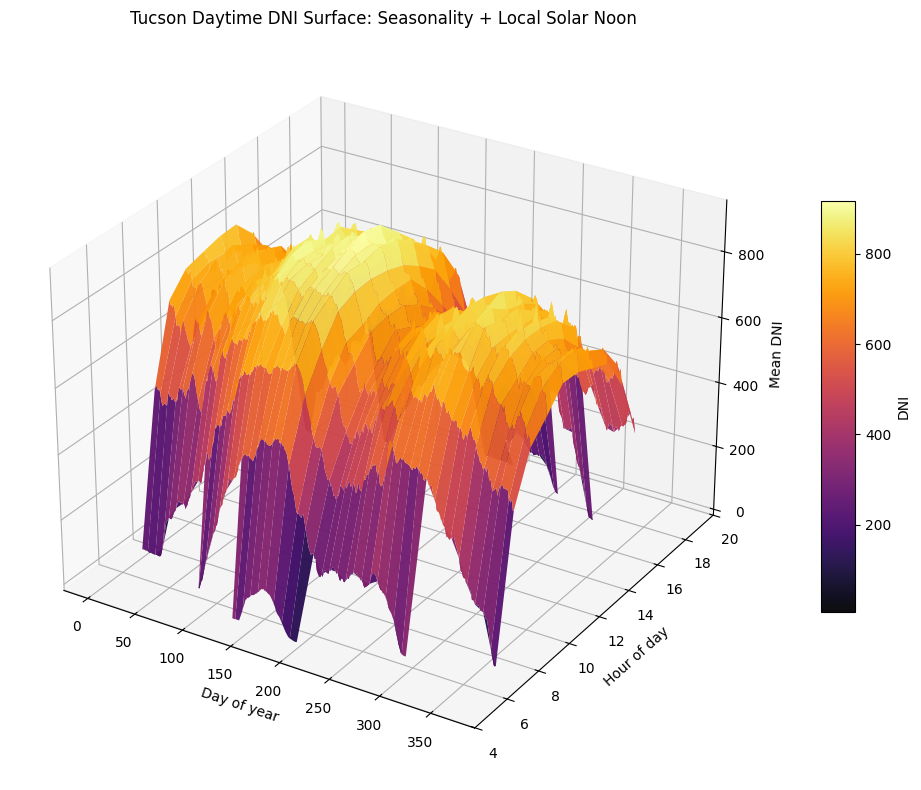

In [96]:
if should_skip_presentation_plots():
    print("Smoke test: skipping 3D seasonal surface plot to keep validation fast.")
else:
    # 3D surface of DNI by hour and day of year
    ## Ref A 3D hour-by-day surface is an interpretable way to inspect the annual solar pattern in local time.

    surface_stats = (
        train_daytime
        .groupby(["hour", "day_of_year"])[CFG.target_col]
        .mean()
        .reset_index()
    )
    surface_pivot = surface_stats.pivot(index="hour", columns="day_of_year", values=CFG.target_col).sort_index()
    surface_pivot = surface_pivot.rolling(window=7, axis=1, min_periods=3).mean()

    X = surface_pivot.columns.to_numpy()
    Y = surface_pivot.index.to_numpy()
    X_grid, Y_grid = np.meshgrid(X, Y)
    Z_grid = surface_pivot.to_numpy()

    fig = plt.figure(figsize=(13, 8))
    ax = fig.add_subplot(111, projection="3d")
    surface = ax.plot_surface(X_grid, Y_grid, Z_grid, cmap="inferno", edgecolor="none", alpha=0.95)
    ax.view_init(elev=28, azim=-58)
    ax.set_title("Tucson Daytime DNI Surface: Seasonality + Local Solar Noon")
    ax.set_xlabel("Day of year")
    ax.set_ylabel("Hour of day")
    ax.set_zlabel("Mean DNI")
    fig.colorbar(surface, shrink=0.55, aspect=12, label="DNI")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "RJV2_dni_daytime_3d_surface.png", dpi=180, bbox_inches="tight")
    plt.show()

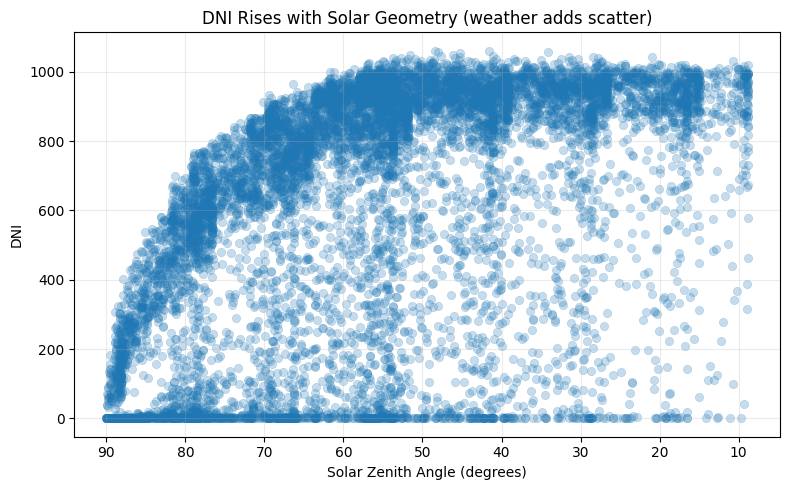

Minimum binned sample count for plotted AOD/RH bins: 222


,aod_bin,mean,median,count,bin_label,use_in_plot
0,"(0.00844, 0.0881]",664.962376,817.0,77903,0.008-0.088,True
1,"(0.0881, 0.166]",516.144691,614.0,27887,0.088-0.166,True
2,"(0.166, 0.244]",385.619929,365.5,3944,0.166-0.244,True
3,"(0.244, 0.322]",336.703851,268.0,753,0.244-0.322,True
4,"(0.322, 0.4]",354.293160,355.0,307,0.322-0.400,True
5,"(0.4, 0.479]",332.024390,293.0,123,0.400-0.479,False
6,"(0.479, 0.557]",364.068182,445.5,44,0.479-0.557,False
7,"(0.557, 0.635]",285.333333,271.5,30,0.557-0.635,False
8,"(0.635, 0.713]",229.615385,136.0,13,0.635-0.713,False
9,"(0.713, 0.791]",400.000000,503.0,13,0.713-0.791,False


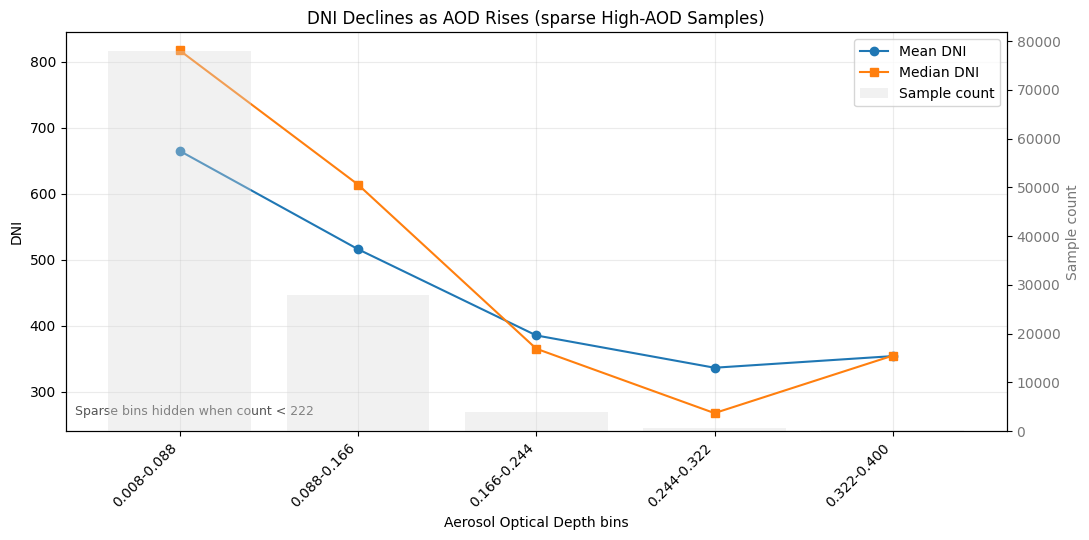

,rh_bin,mean,median,count,bin_label,use_in_plot
0,"(1.906, 6.703]",881.519611,946.0,5456,2-7%,True
1,"(6.703, 11.406]",820.059722,914.0,15053,7-11%,True
2,"(11.406, 16.109]",765.155936,886.5,15904,11-16%,True
3,"(16.109, 20.812]",708.778960,843.0,14658,16-21%,True
4,"(20.812, 25.515]",648.926996,785.0,12465,21-26%,True
5,"(25.515, 30.218]",586.833528,706.0,10272,26-30%,True
6,"(30.218, 34.921]",522.201349,606.0,8597,30-35%,True
7,"(34.921, 39.624]",463.653018,511.5,7156,35-40%,True
8,"(39.624, 44.327]",408.276977,403.0,5690,40-44%,True
9,"(44.327, 49.03]",360.171532,303.0,4419,44-49%,True


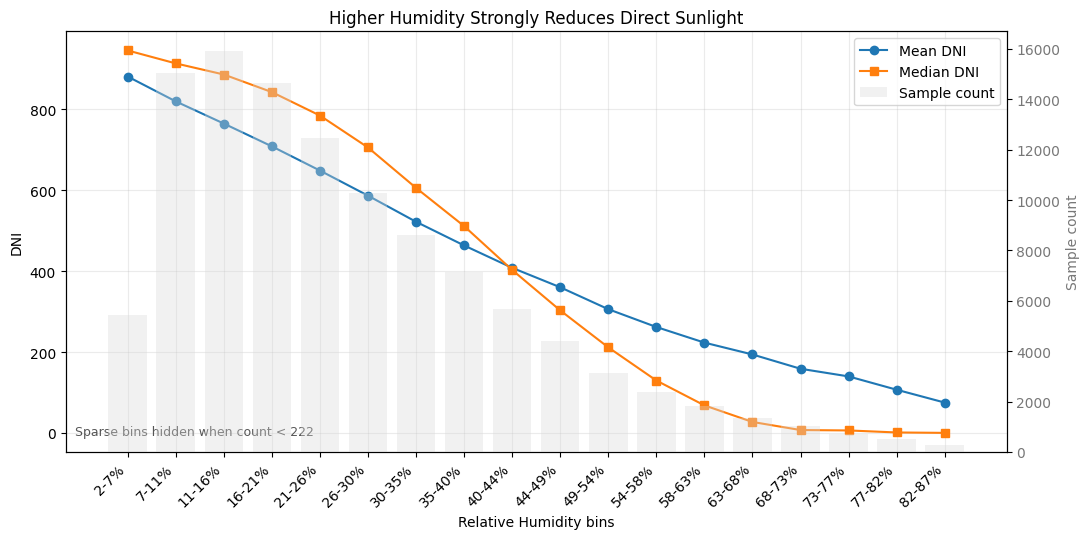

In [97]:
if should_skip_presentation_plots():
    print("Smoke test: skipping daytime DNI relationships with SZA, aerosol optical depth, and relative humidity to keep validation fast.")
else:
    # daytime DNI relationships with SZA, aerosol optical depth, and relative humidity
    ## Ref SZA controls solar geometry; AOD and relative humidity proxy atmospheric attenuation/scattering.
    ## SZA ref: https://www.nrel.gov/grid/solar-resource/solar-position.html
    ## AOD ref: https://gml.noaa.gov/grad/surfrad/aod/

    from scipy import stats


    scatter_n = min(10000, len(train_daytime))
    scatter_df = train_daytime.sample(scatter_n, random_state=42) if len(train_daytime) > scatter_n else train_daytime.copy()

    # Solar zenith angle plot
    scatter_df["sza"] = pd.to_numeric(scatter_df["Solar Zenith Angle"], errors="coerce")

    plt.figure(figsize=(8, 5))
    ax = sns.scatterplot(data=scatter_df, x="sza", y=CFG.target_col, alpha=0.25, edgecolor=None)
    ax.set_title("DNI Rises with Solar Geometry (weather adds scatter)")
    ax.set_xlabel("Solar Zenith Angle (degrees)")
    ax.set_ylabel("DNI")
    ax.grid(alpha=0.25)
    ax.invert_xaxis()
    save_current_plot("RJV2_dni_daytime_vs_sza.png")


    MIN_BIN_COUNT = max(50, int(len(train_daytime) * 0.002))
    print("Minimum binned sample count for plotted AOD/RH bins:", MIN_BIN_COUNT)

    def plot_binned_atmospheric_relationship(source_df, value_col, bin_col, output_csv, output_png, title, xlabel):
        binned = source_df[[value_col, CFG.target_col]].dropna().copy()
        binned[bin_col] = pd.cut(binned[value_col], bins=20)
        stats = (
            binned
            .groupby(bin_col, observed=True)[CFG.target_col]
            .agg(mean="mean", median="median", count="count")
            .reset_index()
        )
        # fix RH bin labels for better presentation
        if value_col == "Relative Humidity":
            stats["bin_label"] = stats[bin_col].apply(lambda x: f"{x.left:.0f}-{x.right:.0f}%")
        elif value_col == "Aerosol Optical Depth":
            stats["bin_label"] = stats[bin_col].apply(lambda x: f"{x.left:.3f}-{x.right:.3f}")
        else:
            stats["bin_label"] = stats[bin_col].astype(str)

        stats["use_in_plot"] = stats["count"] >= MIN_BIN_COUNT
        stats.to_csv(OUTPUT_DIR / output_csv, index=False)
        display(stats)

        plot_stats = stats[stats["use_in_plot"]].copy()
        if plot_stats.empty:
            print(f"No {value_col} bins met MIN_BIN_COUNT={MIN_BIN_COUNT}; skipping plot.")
            return

        fig, ax1 = plt.subplots(figsize=(11, 5.5))
        x = np.arange(len(plot_stats))
        ax2 = ax1.twinx()
        ax2.bar(x, plot_stats["count"], color="#d9d9d9", alpha=0.35, label="Sample count")
        ax2.set_ylabel("Sample count", color="#777777")
        ax2.tick_params(axis="y", labelcolor="#777777")

        ax1.plot(x, plot_stats["mean"], marker="o", label="Mean DNI", color="#1f77b4")
        ax1.plot(x, plot_stats["median"], marker="s", label="Median DNI", color="#ff7f0e")
        ax1.set_title(title)
        ax1.set_xlabel(xlabel)
        ax1.set_ylabel("DNI")
        ax1.set_xticks(x)
        ax1.set_xticklabels(plot_stats["bin_label"], rotation=45, ha="right")
        ax1.grid(alpha=0.25)
        lines1, labels1 = ax1.get_legend_handles_labels()
        lines2, labels2 = ax2.get_legend_handles_labels()
        ax1.legend(lines1 + lines2, labels1 + labels2, loc="best")
        ax1.text(0.01, 0.04, f"Sparse bins hidden when count < {MIN_BIN_COUNT}", transform=ax1.transAxes, fontsize=9, color="#555555")
        plt.tight_layout()
        plt.savefig(OUTPUT_DIR / output_png, dpi=180, bbox_inches="tight")
        plt.show()

    if "Aerosol Optical Depth" in train_daytime.columns:
        plot_binned_atmospheric_relationship(
            train_daytime,
            value_col="Aerosol Optical Depth",
            bin_col="aod_bin",
            output_csv="RJV2_dni_daytime_aod_bins.csv",
            output_png="RJV2_dni_daytime_vs_aod.png",
            title="DNI Declines as AOD Rises (sparse High-AOD Samples)",
            xlabel="Aerosol Optical Depth bins",
        )
    else:
        print("Aerosol Optical Depth not found; skipping AOD plot.")

    if "Relative Humidity" in train_daytime.columns:
        plot_binned_atmospheric_relationship(
            train_daytime,
            value_col="Relative Humidity",
            bin_col="rh_bin",
            output_csv="RJV2_dni_daytime_relative_humidity_bins.csv",
            output_png="RJV2_dni_daytime_vs_relative_humidity.png",
            title="Higher Humidity Strongly Reduces Direct Sunlight",
            xlabel="Relative Humidity bins",
        )
    else:
        print("Relative Humidity not found; skipping humidity plot.")

,cloud_type_label,mean,median,std,count,frequency_pct,one_hot_column
0,Clear,795.428884,875.0,225.440610,72269,65.087271,cloud_type_clear
1,Overlapping,346.012335,352.0,265.121950,9404,8.469478,cloud_type_overlapping
2,Cirrus,223.872882,140.0,235.500791,7969,7.177081,cloud_type_cirrus
3,Water,220.844289,178.0,205.856181,5446,4.904804,cloud_type_water
4,Probably Clear,623.225347,693.0,292.167858,5405,4.867878,cloud_type_probably_clear
5,Super-Cooled Water,52.599067,2.0,96.393272,5360,4.827350,cloud_type_super_cooled_water
6,Opaque Ice,38.296663,2.0,84.747102,3536,3.184610,cloud_type_opaque_ice
7,Fog,484.232824,551.0,231.673419,1310,1.179819,cloud_type_fog
8,Overshooting,8.212871,0.0,26.821674,202,0.181926,cloud_type_overshooting
9,Mixed,61.867188,26.0,80.630134,128,0.115280,cloud_type_mixed


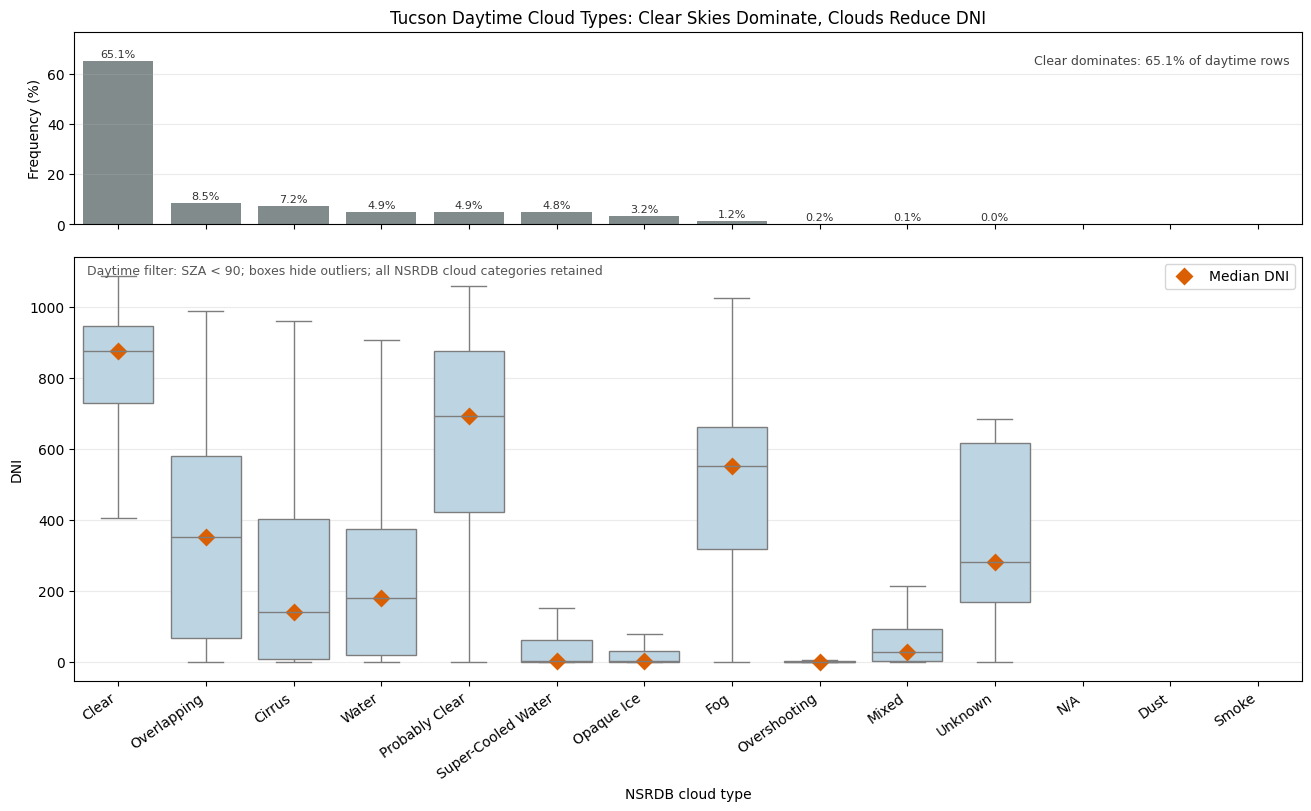

In [98]:
if should_skip_presentation_plots():
    print("Smoke test: skipping daytime DNI by NSRDB cloud type to keep validation fast.")
else:
    # daytime DNI by NSRDB cloud type
    ## Daytime uses Solar Zenith Angle < 90. NSRDB cloud type is categorical, so this plot summarizes DNI by label rather than treating the integer codes as ordinal.
    ## Ref NSRDB API CSV metadata includes cloud type labels: https://developer.nrel.gov/docs/solar/nsrdb/psm3-download/

    if "cloud_type_label" not in train_daytime.columns:
        if "Cloud Type" not in train_daytime.columns:
            raise KeyError("Missing both cloud_type_label and Cloud Type; cannot plot DNI by cloud type.")
        cloud_codes = pd.to_numeric(train_daytime["Cloud Type"], errors="coerce").fillna(-15).astype(int)
        train_daytime["cloud_type_label"] = cloud_codes.map(CLOUD_TYPE_LABELS).fillna("Unknown")

    observed_cloud_stats = (
        train_daytime
        .dropna(subset=["cloud_type_label", CFG.target_col])
        .groupby("cloud_type_label", observed=True)[CFG.target_col]
        .agg(mean="mean", median="median", std="std", count="count")
    )
    cloud_stats = (
        pd.DataFrame({"cloud_type_label": CLOUD_TYPE_ORDER})
        .merge(observed_cloud_stats, left_on="cloud_type_label", right_index=True, how="left")
    )
    cloud_stats["count"] = cloud_stats["count"].fillna(0).astype(int)
    cloud_stats["frequency_pct"] = np.where(len(train_daytime) > 0, cloud_stats["count"] / len(train_daytime) * 100, 0.0)
    cloud_stats["one_hot_column"] = cloud_stats["cloud_type_label"].map(lambda label: f"cloud_type_{cloud_type_slug(label)}")
    cloud_stats = cloud_stats.sort_values(["count", "median"], ascending=[False, False], na_position="last").reset_index(drop=True)
    cloud_stats.to_csv(OUTPUT_DIR / "RJV2_dni_daytime_cloud_type_summary.csv", index=False)
    display(cloud_stats)

    cloud_order = cloud_stats["cloud_type_label"].tolist()
    plot_data = train_daytime.dropna(subset=["cloud_type_label", CFG.target_col]).copy()
    plot_data["cloud_type_label"] = pd.Categorical(plot_data["cloud_type_label"], categories=cloud_order, ordered=True)

    fig, (ax_freq, ax_dni) = plt.subplots(
        2, 1, figsize=(13, 8), sharex=True, constrained_layout=True,
        gridspec_kw={"height_ratios": [1, 2.2], "hspace": 0.06}
    )

    sns.barplot(
        data=cloud_stats,
        x="cloud_type_label",
        y="frequency_pct",
        order=cloud_order,
        color="#7f8c8d",
        ax=ax_freq,
    )
    ax_freq.set_title("Tucson Daytime Cloud Types: Clear Skies Dominate, Clouds Reduce DNI")
    ax_freq.set_xlabel("")
    ax_freq.set_ylabel("Frequency (%)")
    ax_freq.grid(axis="y", alpha=0.25)
    for patch, pct, count in zip(ax_freq.patches, cloud_stats["frequency_pct"], cloud_stats["count"]):
        if count > 0:
            ax_freq.text(
                patch.get_x() + patch.get_width() / 2,
                patch.get_height() + 0.8,
                f"{pct:.1f}%",
                ha="center",
                va="bottom",
                fontsize=8,
                rotation=0,
                color="#333333",
            )
    ax_freq.set_ylim(0, cloud_stats["frequency_pct"].max() * 1.18)
    ax_freq.text(
        0.99,
        0.88,
        f"Clear dominates: {cloud_stats.loc[cloud_stats['cloud_type_label'].eq('Clear'), 'frequency_pct'].iloc[0]:.1f}% of daytime rows",
        transform=ax_freq.transAxes,
        ha="right",
        va="top",
        fontsize=9,
        color="#444444",
    )

    sns.boxplot(
        data=plot_data,
        x="cloud_type_label",
        y=CFG.target_col,
        order=cloud_order,
        color="#b7d7e8",
        showfliers=False,
        ax=ax_dni,
    )
    sns.pointplot(
        data=cloud_stats,
        x="cloud_type_label",
        y="median",
        order=cloud_order,
        color="#d95f02",
        markers="D",
        linestyles="none",
        errorbar=None,
        ax=ax_dni,
        label="Median DNI",
    )
    ax_dni.set_xlabel("NSRDB cloud type")
    ax_dni.set_ylabel("DNI")
    ax_dni.grid(axis="y", alpha=0.25)
    ax_dni.text(0.01, 0.96, "Daytime filter: SZA < 90; boxes hide outliers; all NSRDB cloud categories retained", transform=ax_dni.transAxes, fontsize=9, color="#555555")
    ax_dni.tick_params(axis="x", rotation=35)
    for label in ax_dni.get_xticklabels():
        label.set_ha("right")

    handles, labels = ax_dni.get_legend_handles_labels()
    if handles:
        ax_dni.legend(handles[-1:], labels[-1:], loc="upper right")
    plt.savefig(OUTPUT_DIR / "RJV2_cloud_type_frequency_and_dni.png", dpi=180, bbox_inches="tight")
    plt.savefig(OUTPUT_DIR / "RJV2_dni_daytime_by_cloud_type.png", dpi=180, bbox_inches="tight")
    plt.show()


,cloud_type_group,mean,median,std,count,frequency_pct,one_hot_column
0,Clear-like,783.445979,869.0,234.831271,77674,69.955149,cloud_group_clear_like
1,Thick/complex cloud,278.530376,204.0,272.593028,14452,13.015833,cloud_group_thick_complex_cloud
2,Liquid/mixed cloud,136.507042,42.0,181.093906,10934,9.847434,cloud_group_liquid_mixed_cloud
3,Thin high cloud,223.872882,140.0,235.500791,7969,7.177081,cloud_group_thin_high_cloud
4,Rare/unknown,349.800000,282.0,292.416142,5,0.004503,cloud_group_rare_unknown


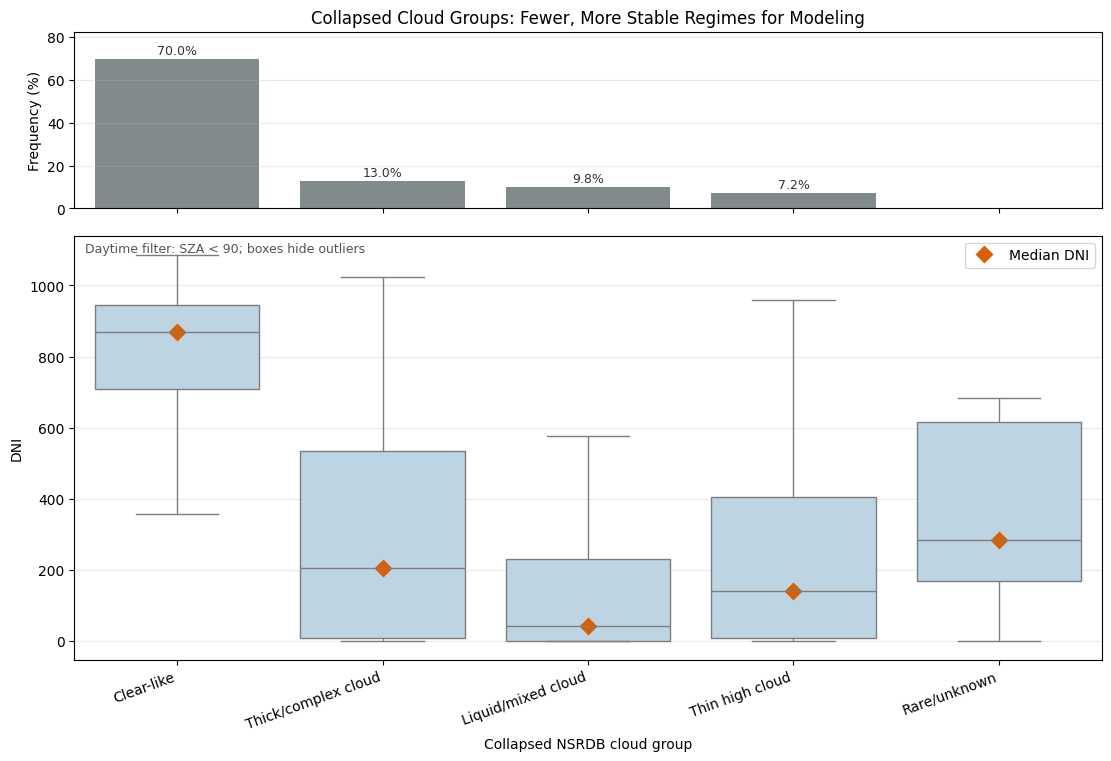

In [99]:
if should_skip_presentation_plots():
    print("Smoke test: skipping daytime DNI by collapsed cloud group to keep validation fast.")
else:
    # daytime DNI by collapsed cloud groups
    ## Grouping rare/similar NSRDB cloud types reduces sparsity and gives a more stable modeling feature than full one-hot cloud type.
    ## Ref Professor feedback recommended checking feature redundancy and avoiding overly sparse predictors.

    if "cloud_type_group" not in train_daytime.columns:
        if "cloud_type_label" not in train_daytime.columns:
            if "Cloud Type" not in train_daytime.columns:
                raise KeyError("Missing cloud fields; cannot plot DNI by collapsed cloud group.")
            cloud_codes = pd.to_numeric(train_daytime["Cloud Type"], errors="coerce").fillna(-15).astype(int)
            train_daytime["cloud_type_label"] = cloud_codes.map(CLOUD_TYPE_LABELS).fillna("Unknown")
        train_daytime["cloud_type_group"] = train_daytime["cloud_type_label"].map(CLOUD_TYPE_GROUPS).fillna("Rare/unknown")

    observed_group_stats = (
        train_daytime
        .dropna(subset=["cloud_type_group", CFG.target_col])
        .groupby("cloud_type_group", observed=True)[CFG.target_col]
        .agg(mean="mean", median="median", std="std", count="count")
    )
    cloud_group_stats = (
        pd.DataFrame({"cloud_type_group": CLOUD_GROUP_ORDER})
        .merge(observed_group_stats, left_on="cloud_type_group", right_index=True, how="left")
    )
    cloud_group_stats["count"] = cloud_group_stats["count"].fillna(0).astype(int)
    cloud_group_stats["frequency_pct"] = np.where(len(train_daytime) > 0, cloud_group_stats["count"] / len(train_daytime) * 100, 0.0)
    cloud_group_stats["one_hot_column"] = cloud_group_stats["cloud_type_group"].map(lambda label: f"cloud_group_{cloud_type_slug(label)}")
    cloud_group_stats = cloud_group_stats.sort_values(["count", "median"], ascending=[False, False], na_position="last").reset_index(drop=True)
    cloud_group_stats.to_csv(OUTPUT_DIR / "RJV2_dni_daytime_cloud_group_summary.csv", index=False)
    display(cloud_group_stats)

    group_order = cloud_group_stats["cloud_type_group"].tolist()
    group_plot_data = train_daytime.dropna(subset=["cloud_type_group", CFG.target_col]).copy()
    group_plot_data["cloud_type_group"] = pd.Categorical(group_plot_data["cloud_type_group"], categories=group_order, ordered=True)

    fig, (ax_freq, ax_dni) = plt.subplots(
        2, 1, figsize=(11, 7.5), sharex=True, constrained_layout=True,
        gridspec_kw={"height_ratios": [1, 2.4], "hspace": 0.05}
    )

    sns.barplot(
        data=cloud_group_stats,
        x="cloud_type_group",
        y="frequency_pct",
        order=group_order,
        color="#7f8c8d",
        ax=ax_freq,
    )
    ax_freq.set_title("Collapsed Cloud Groups: Fewer, More Stable Regimes for Modeling")
    ax_freq.set_xlabel("")
    ax_freq.set_ylabel("Frequency (%)")
    ax_freq.grid(axis="y", alpha=0.25)
    for patch, pct, count in zip(ax_freq.patches, cloud_group_stats["frequency_pct"], cloud_group_stats["count"]):
        if pct >= 0.1:
            ax_freq.text(
                patch.get_x() + patch.get_width() / 2,
                patch.get_height() + 0.8,
                f"{pct:.1f}%",
                ha="center",
                va="bottom",
                fontsize=9,
                color="#333333",
            )
    ax_freq.set_ylim(0, cloud_group_stats["frequency_pct"].max() * 1.18)

    sns.boxplot(
        data=group_plot_data,
        x="cloud_type_group",
        y=CFG.target_col,
        order=group_order,
        color="#b7d7e8",
        showfliers=False,
        ax=ax_dni,
    )
    sns.pointplot(
        data=cloud_group_stats,
        x="cloud_type_group",
        y="median",
        order=group_order,
        color="#d95f02",
        markers="D",
        linestyles="none",
        errorbar=None,
        ax=ax_dni,
        label="Median DNI",
    )
    ax_dni.set_xlabel("Collapsed NSRDB cloud group")
    ax_dni.set_ylabel("DNI")
    ax_dni.grid(axis="y", alpha=0.25)
    ax_dni.text(0.01, 0.96, "Daytime filter: SZA < 90; boxes hide outliers", transform=ax_dni.transAxes, fontsize=9, color="#555555")
    ax_dni.tick_params(axis="x", rotation=20)
    for label in ax_dni.get_xticklabels():
        label.set_ha("right")
    handles, labels = ax_dni.get_legend_handles_labels()
    if handles:
        ax_dni.legend(handles[-1:], labels[-1:], loc="upper right")

    plt.savefig(OUTPUT_DIR / "RJV2_cloud_group_frequency_and_dni.png", dpi=180, bbox_inches="tight")
    plt.show()


,sample_count,Relative Humidity,Temperature,Dew Point,Aerosol Optical Depth,Precipitable Water,Wind Speed,Solar Zenith Angle,Clearsky DNI,sample_pct
cloud_type_label,,,,,,,,,,
Clear,72269,18.790,27.4,-0.50,0.0630,1.1,2.8,55.110,879.0,65.087271
Overlapping,9404,27.105,28.5,6.10,0.0880,2.1,2.7,55.660,819.0,8.469478
Cirrus,7969,31.100,22.1,2.30,0.0710,1.4,2.6,64.900,777.0,7.177081
Water,5446,30.220,27.3,6.90,0.0820,2.1,2.7,62.335,773.0,4.904804
Probably Clear,5405,28.830,23.9,1.40,0.0670,1.2,2.4,71.650,693.0,4.867878
Super-Cooled Water,5360,41.910,19.7,5.20,0.0780,1.7,2.7,65.135,759.0,4.827350
Opaque Ice,3536,37.435,27.9,11.10,0.1020,3.0,2.6,59.815,755.5,3.184610
Fog,1310,24.355,30.2,4.50,0.0760,1.7,3.2,44.565,894.0,1.179819
Overshooting,202,44.235,30.7,16.05,0.1110,4.2,2.5,61.275,717.0,0.181926


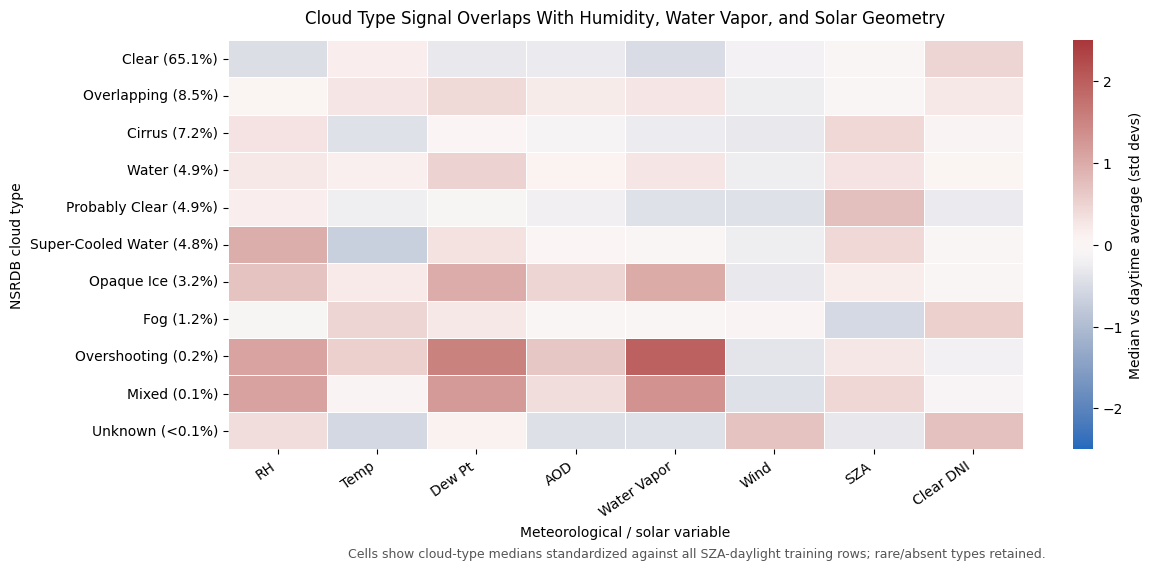

In [100]:
if should_skip_presentation_plots():
    print("Smoke test: skipping cloud type meteorology profile to keep validation fast.")
else:
    # cloud type meteorology profile

    ## Cloud type is a categorical satellite-derived atmospheric condition. Comparing it with humidity, temperature, aerosol, and clear-sky geometry helps diagnose whether it adds unique information or overlaps with existing meteorological predictors.
    ## Ref Professor feedback recommended checking feature redundancy; standardized group profiles are
    ### compact alternative to crowded categorical pairplots

    cloud_meteo_vars = [
        "Relative Humidity",
        "Temperature",
        "Dew Point",
        "Aerosol Optical Depth",
        "Precipitable Water",
        "Wind Speed",
        "Solar Zenith Angle",
        "Clearsky DNI",
    ]
    cloud_meteo_vars = [c for c in cloud_meteo_vars if c in train_daytime.columns]

    if not cloud_meteo_vars:
        raise KeyError("No meteorological columns available for cloud type profile.")

    if "cloud_type_label" not in train_daytime.columns:
        if "Cloud Type" not in train_daytime.columns:
            raise KeyError("Missing both cloud_type_label and Cloud Type; cannot profile cloud types.")
        cloud_codes = pd.to_numeric(train_daytime["Cloud Type"], errors="coerce").fillna(-15).astype(int)
        train_daytime["cloud_type_label"] = cloud_codes.map(CLOUD_TYPE_LABELS).fillna("Unknown")

    profile_order = cloud_stats["cloud_type_label"].tolist() if "cloud_stats" in globals() else CLOUD_TYPE_ORDER

    profile_base = train_daytime.dropna(subset=["cloud_type_label"]).copy()
    for col in cloud_meteo_vars:
        profile_base[col] = pd.to_numeric(profile_base[col], errors="coerce")

    cloud_profile = (
        profile_base
        .groupby("cloud_type_label", observed=True)[cloud_meteo_vars]
        .median()
        .reindex(profile_order)
    )

    cloud_profile_counts = (
        profile_base
        .groupby("cloud_type_label", observed=True)
        .size()
        .reindex(profile_order)
        .fillna(0)
        .astype(int)
    )

    cloud_profile.insert(0, "sample_count", cloud_profile_counts)
    cloud_profile["sample_pct"] = np.where(
        cloud_profile["sample_count"].sum() > 0,
        cloud_profile["sample_count"] / cloud_profile["sample_count"].sum() * 100,
        0.0,
    )

    cloud_profile.to_csv(OUTPUT_DIR / "RJV2_cloud_type_meteorology_profile.csv")
    display(cloud_profile)

    ref_mean = profile_base[cloud_meteo_vars].mean()
    ref_std = profile_base[cloud_meteo_vars].std().replace(0, np.nan)

    cloud_profile_z = ((cloud_profile[cloud_meteo_vars] - ref_mean) / ref_std).clip(-2.5, 2.5)
    cloud_profile_z = cloud_profile_z.dropna(how="all")

    # Short display names keep the heatmap readable in slides/report figures.
    short_var_names = {
        "Relative Humidity": "RH",
        "Temperature": "Temp",
        "Dew Point": "Dew Pt",
        "Aerosol Optical Depth": "AOD",
        "Precipitable Water": "Water Vapor",
        "Wind Speed": "Wind",
        "Solar Zenith Angle": "SZA",
        "Clearsky DNI": "Clear DNI",
    }

    plot_heatmap = cloud_profile_z.rename(columns=short_var_names).copy()

    # Put frequency share directly in y-axis labels.
    y_labels = []
    for label in plot_heatmap.index:
        pct = float(cloud_profile.loc[label, "sample_pct"])

        if pct == 0:
            pct_label = "0%"
        elif pct < 0.1:
            pct_label = "<0.1%"
        else:
            pct_label = f"{pct:.1f}%"

        y_labels.append(f"{label} ({pct_label})")

    fig, ax = plt.subplots(figsize=(12.5, max(6.2, 0.5 * len(plot_heatmap))))

    sns.heatmap(
        plot_heatmap,
        cmap="vlag",
        center=0,
        vmin=-2.5,
        vmax=2.5,
        linewidths=0.5,
        linecolor="white",
        cbar_kws={"label": "Median vs daytime average (std devs)"},
        ax=ax,
    )

    ax.set_title("Cloud Type Signal Overlaps With Humidity, Water Vapor, and Solar Geometry", pad=12)
    ax.set_xlabel("Meteorological / solar variable")
    ax.set_ylabel("NSRDB cloud type")
    ax.set_yticklabels(y_labels, rotation=0)

    ax.tick_params(axis="x", rotation=35)
    for label in ax.get_xticklabels():
        label.set_ha("right")

    fig.subplots_adjust(bottom=0.22, right=0.92)

    fig.text(
        0.5,
        0.04,
        "Cells show cloud-type medians standardized against all SZA-daylight training rows; rare/absent types retained.",
        ha="center",
        va="bottom",
        fontsize=9,
        color="#555555",
    )

    plt.savefig(OUTPUT_DIR / "RJV2_cloud_type_meteorology_profile.png", dpi=180, bbox_inches="tight")
    plt.show()


In [101]:
# Save data ready for modeling 


model_frame_path = PROCESSED_DIR / f"RJV2_{CFG.location_slug}_model_frame.parquet"
model_frame_csv_path = PROCESSED_DIR / f"RJV2_{CFG.location_slug}_model_frame.csv"
metadata_path = PROCESSED_DIR / f"RJV2_{CFG.location_slug}_feature_metadata.json"

feature_df.to_parquet(model_frame_path, index=False)
feature_df.to_csv(model_frame_csv_path, index=False)
metadata = {
    "config": asdict(CFG),
    "feature_sets": feature_sets,
    "leakage_policy": {
        "current_irradiance_blocklist": sorted(CURRENT_IRRADIANCE_BLOCKLIST),
        "historical_irradiance_prefixes": list(HISTORICAL_IRRADIANCE_PREFIXES),
        "univariate_exception": "Raw DNI is allowed only as the historical sequence input; target timestamp is shifted into the future in the modeling notebook.",
        "multivariate_rule": "Multivariate features may include irradiance only through explicit lag/rolling/difference features; current DNI/GHI/DHI/UV/current clear-sky fields are blocked.",
        "univariate_audit_violations": irradiance_policy_violations(feature_sets["univariate"], allow_univariate_dni_sequence=True),
        "multivariate_audit_violations": irradiance_policy_violations(feature_sets["multivariate"], allow_univariate_dni_sequence=False),
    },
    "notes": {
        "univariate": "Pure historical DNI sequence for professor-facing comparison; no target-timestamp DNI is available to the model.",
        "multivariate": "Lagged/rolling DNI plus time, weather, solar geometry, atmospheric variables, lagged clear-sky context, and optional cloud encodings. Current DNI/GHI/DHI/UV/current clear-sky irradiance are excluded as direct features.",
        "scaling": "Modeling notebook fits scalers on training rows per horizon and feature set to avoid leakage."
    }
}
metadata_path.write_text(json.dumps(metadata, indent=2), encoding="utf-8")

print("Saved model frame parquet:", model_frame_path)
print("Saved model frame csv:", model_frame_csv_path)
print("Saved feature metadata:", metadata_path)
print("Shape:", feature_df.shape)


Saved model frame parquet: <repo>/data/processed/RJV2/tucson_az/RJV2_tucson_az_model_frame.parquet
Saved model frame csv: <repo>/data/processed/RJV2/tucson_az/RJV2_tucson_az_model_frame.csv
Saved feature metadata: <repo>/data/processed/RJV2/tucson_az/RJV2_tucson_az_feature_metadata.json
Shape: (236520, 95)


In [ ]:
# team friendly csv exports

USE_EXPORT_CACHE = True # if export files already cached, reuse vs rebuild
FORCE_REBUILD_EXPORT_CACHE = False # False to build files only if not in cache 

TEAM_EXPORT_DIR = PROCESSED_DIR
TEAM_EXPORT_DIR.mkdir(parents=True, exist_ok=True)

full_csv_src = PROCESSED_DIR / f"RJV2_{CFG.location_slug}_nsrdb_all_years_local.csv"
full_parquet_src = PROCESSED_DIR / f"RJV2_{CFG.location_slug}_nsrdb_all_years_local.parquet"

full_csv_dst = TEAM_EXPORT_DIR / "nsrdb_all_years.csv"
full_parquet_dst = TEAM_EXPORT_DIR / "nsrdb_all_years.parquet"

SPLIT_EXPORT_DIR = PROJECT_ROOT / "data"
train_path = SPLIT_EXPORT_DIR / "train_solar_data.csv.gz"
valid_path = SPLIT_EXPORT_DIR / "valid_solar_data.csv.gz"
test_path = SPLIT_EXPORT_DIR / "test_solar_data.csv.gz"

TEAM_EXPORT_FILES = [full_csv_dst, full_parquet_dst, train_path, valid_path, test_path]
export_cache_exists = all(path.exists() for path in TEAM_EXPORT_FILES)

# Try to resolve a cached feature frame if this kernel was restarted.
resolved_feature_cache_path = None
if "FEATURE_CACHE_PATH" in globals():
    resolved_feature_cache_path = FEATURE_CACHE_PATH
else:
    candidate_feature_cache_paths = sorted(OUTPUT_DIR.glob("RJV2_feature_frame_*.parquet"))
    if candidate_feature_cache_paths:
        resolved_feature_cache_path = candidate_feature_cache_paths[-1]

if USE_EXPORT_CACHE and export_cache_exists and not FORCE_REBUILD_EXPORT_CACHE:
    print("Using existing team-friendly exports:")
    for path in TEAM_EXPORT_FILES:
        print(" -", path)
else:
    # Make sure feature_df exists if we need to rebuild train/valid/test exports.
    if "feature_df" not in globals() or feature_df is None:
        if resolved_feature_cache_path is not None and resolved_feature_cache_path.exists():
            print(f"Loading feature_df from cache: {resolved_feature_cache_path}")
            feature_df = pd.read_parquet(resolved_feature_cache_path)
        else:
            raise FileNotFoundError(
                "feature_df is not available in memory and no feature cache was found. "
                "Run the feature engineering block first, or enable/save feature cache there."
            )

    # Full files
    if full_csv_src.exists():
        pd.read_csv(full_csv_src).to_csv(full_csv_dst, index=False)
        print("Saved:", full_csv_dst)
    else:
        print("Missing full CSV source:", full_csv_src)

    if full_parquet_src.exists():
        pd.read_parquet(full_parquet_src).to_parquet(full_parquet_dst, index=False)
        print("Saved:", full_parquet_dst)
    else:
        print("Missing full parquet source:", full_parquet_src)

    # Train/Valid/Test sets
    if "split" not in feature_df.columns:
        raise KeyError(
            "feature_df does not contain a 'split' column, which is required for team-friendly exports."
        )

    train_export = feature_df[feature_df["split"] == "train"].copy()
    valid_export = feature_df[feature_df["split"] == "validation"].copy()
    test_export = feature_df[feature_df["split"] == "test"].copy()

    train_export.to_csv(train_path, index=False)
    valid_export.to_csv(valid_path, index=False)
    test_export.to_csv(test_path, index=False)

    print("Saved:", train_path, train_export.shape)
    print("Saved:", valid_path, valid_export.shape)
    print("Saved:", test_path, test_export.shape)

print("Note: for horizon/lookback models, keep the full model frame too... preserves boundary rows needed for lagged sequences")


In [103]:
# Data dictionary after preprocessing and feature engineering

### documents raw/downloaded fields, engineered features, leakage policy, training status, missingness, ranges, definitions, and source notes

NSRDB_SOURCE_URL = "https://developer.nrel.gov/docs/solar/nsrdb/"
NSRDB_PSM3_URL = "https://developer.nrel.gov/docs/solar/nsrdb/psm3-download/"
CYCLICAL_FEATURE_URL = "https://scikit-learn.org/stable/auto_examples/applications/plot_cyclical_feature_engineering.html"
TIME_SERIES_FEATURE_URL = "https://otexts.com/fpp3/"

RAW_COLUMN_DEFINITIONS = {
    "Year": "Calendar year from the NSRDB local-standard-time record.",
    "Month": "Calendar month from the NSRDB local-standard-time record.",
    "Day": "Calendar day from the NSRDB local-standard-time record.",
    "Hour": "Hour of day from the NSRDB local-standard-time record.",
    "Minute": "Minute field from the NSRDB local-standard-time record.",
    "timestamp": "Datetime assembled from Year, Month, Day, Hour, and Minute; utc=false request returns local standard time for Tucson.",
    "Temperature": "Ambient air temperature at the site.",
    "Alpha": "Angstrom alpha aerosol parameter, describing wavelength dependence of aerosol optical depth.",
    "Aerosol Optical Depth": "Column aerosol optical depth; larger values generally indicate more atmospheric aerosol extinction.",
    "Asymmetry": "Aerosol scattering asymmetry factor used by NSRDB physical solar modeling.",
    "Clearsky DHI": "Diffuse horizontal irradiance expected under clear-sky conditions.",
    "Clearsky DNI": "Direct normal irradiance expected under clear-sky conditions.",
    "Clearsky GHI": "Global horizontal irradiance expected under clear-sky conditions.",
    "Cloud Fill Flag": "NSRDB quality/fill flag associated with cloud inputs.",
    "Cloud Type": "NSRDB categorical cloud type code; encoded separately in preprocessing rather than treated as ordinal.",
    "Dew Point": "Dew point temperature, a moisture-related atmospheric variable.",
    "DHI": "Diffuse horizontal irradiance observed/estimated for the all-sky condition.",
    "DNI": "Direct normal irradiance, the project target variable.",
    "Fill Flag": "NSRDB quality/fill flag for the data record.",
    "GHI": "Global horizontal irradiance observed/estimated for the all-sky condition.",
    "Ozone": "Column ozone amount used in atmospheric irradiance modeling.",
    "Relative Humidity": "Relative humidity near the surface.",
    "Solar Zenith Angle": "Angle between the sun and the local vertical; values below 90 degrees indicate sun above horizon.",
    "SSA": "Single scattering albedo, an aerosol optical property used in radiation transfer.",
    "Surface Albedo": "Fraction of incident shortwave radiation reflected by the surface.",
    "Pressure": "Atmospheric pressure at the site.",
    "Precipitable Water": "Total column water vapor; useful for atmospheric absorption and humidity regimes.",
    "Wind Direction": "Wind direction at the site.",
    "Wind Speed": "Wind speed at the site.",
    "Global Horizontal UV Irradiance (280-400nm)": "Global horizontal ultraviolet irradiance integrated over 280-400 nm.",
    "Global Horizontal UV Irradiance (295-385nm)": "Global horizontal ultraviolet irradiance integrated over 295-385 nm.",
    "source_file": "Local cached annual NSRDB CSV file used to build the combined dataset.",
}

CURRENT_IRRADIANCE_BLOCKLIST_FOR_DICT = set(globals().get("CURRENT_IRRADIANCE_BLOCKLIST", {
    "DNI", "GHI", "DHI", "Clearsky DNI", "Clearsky GHI", "Clearsky DHI",
    "Global Horizontal UV Irradiance (280-400nm)",
    "Global Horizontal UV Irradiance (295-385nm)",
}))
HISTORICAL_IRRADIANCE_PREFIXES_FOR_DICT = tuple(globals().get("HISTORICAL_IRRADIANCE_PREFIXES", (
    "dni_lag_", "dni_roll_", "dni_diff_",
    "ghi_lag_", "ghi_roll_", "ghi_diff_",
    "dhi_lag_", "dhi_roll_", "dhi_diff_",
    "clear_dni_lag_", "clear_index_lag_", "dni_vs_clear_",
)))

OPTIONAL_CLOUD_TYPE_COLS = set(globals().get("ALL_CLOUD_TYPE_COLS", []))
OPTIONAL_CLOUD_GROUP_COLS = set(globals().get("ALL_CLOUD_GROUP_COLS", []))
SUPPORT_COLUMNS_FOR_DICT = set(globals().get("SUPPORT_COLS", ["Clearsky DNI"]))


def raw_column_definition(column: str) -> str:
    return RAW_COLUMN_DEFINITIONS.get(column, "NSRDB downloaded attribute; see NREL NSRDB field documentation.")


def raw_column_source(column: str) -> str:
    if column in {"timestamp", "source_file"}:
        return "Project-derived from NSRDB annual CSV files."
    if column == "Cloud Type":
        return NSRDB_PSM3_URL
    return NSRDB_SOURCE_URL


def infer_feature_role(column: str) -> str:
    if column == CFG.timestamp_col:
        return "timestamp"
    if column == CFG.target_col:
        return "target"
    if column == "split":
        return "split_label"
    if column == "is_sza_daylight":
        return "evaluation_flag"
    if column == "cloud_type_label":
        return "categorical_cloud_type_label"
    if column == "cloud_type_group":
        return "categorical_cloud_type_group"
    if column.startswith("cloud_group_"):
        return "cloud_group_one_hot_feature"
    if column.startswith("cloud_type_"):
        return "cloud_type_one_hot_feature"
    if column == "day_of_year":
        return "calendar_time_feature"
    if column.startswith(("hour_", "day_of_year_", "month_")):
        return "cyclical_time_feature"
    if column.startswith("dni_lag_"):
        return "target_lag_feature"
    if column.startswith("dni_roll_"):
        return "target_rolling_feature"
    if column.startswith("dni_diff_"):
        return "target_difference_feature"
    if column.startswith(("clear_dni_lag_", "clear_index_lag_", "dni_vs_clear_")):
        return "clear_sky_historical_feature"
    if column in RAW_COLUMN_DEFINITIONS:
        if column in {"GHI", "DHI"}:
            return "downloaded_irradiance_proxy_excluded"
        if column.startswith("Clearsky"):
            return "downloaded_clear_sky_support_or_excluded"
        return "raw_downloaded_field"
    return "engineered_or_model_ready_feature"


def training_input_status(column: str) -> str:
    in_uni = column in feature_sets.get("univariate", [])
    in_multi = column in feature_sets.get("multivariate", [])
    in_frame = column in feature_df.columns
    lower = column.lower()
    historical_irradiance = lower.startswith(HISTORICAL_IRRADIANCE_PREFIXES_FOR_DICT)

    if column == CFG.target_col:
        return "target; historical sequence input for univariate only; blocked as current multivariate input"
    if column in CURRENT_IRRADIANCE_BLOCKLIST_FOR_DICT and column != CFG.target_col:
        if column in SUPPORT_COLUMNS_FOR_DICT:
            return "support_only_current_value; used for baseline and lag engineering, not direct training input"
        return "excluded_from_training_current_irradiance_proxy"
    if historical_irradiance:
        return "allowed_historical_irradiance_feature"
    if in_uni and in_multi:
        return "training_input_univariate_and_multivariate"
    if in_uni:
        return "training_input_univariate_historical_sequence"
    if in_multi:
        return "training_input_multivariate"
    if column in OPTIONAL_CLOUD_TYPE_COLS:
        return "optional_training_input_when_cloud_type_encoding_one_hot"
    if column in OPTIONAL_CLOUD_GROUP_COLS:
        return "optional_training_input_when_cloud_type_encoding_grouped"
    if column in {"split", "is_sza_daylight"}:
        return "split_or_evaluation_flag_not_model_input"
    if column in {"cloud_type_label", "cloud_type_group"}:
        return "descriptive_cloud_label_not_direct_model_input"
    if column in {"Year", "Month", "Day", "Hour", "Minute", "source_file"}:
        return "raw_index_or_lineage_field_not_in_model_frame"
    if in_frame:
        return "available_in_model_frame_not_training_input"
    return "downloaded_raw_field_not_used_for_training"


def leakage_policy_note(column: str) -> str:
    lower = column.lower()
    if column == CFG.target_col:
        return "DNI is the target. It is allowed only as historical sequence context for univariate; multivariate uses dni_lag/rolling/diff features instead of current DNI."
    if column in {"GHI", "DHI", "Clearsky GHI", "Clearsky DHI", "Global Horizontal UV Irradiance (280-400nm)", "Global Horizontal UV Irradiance (295-385nm)"}:
        return "Blocked as a current-time irradiance proxy per leakage/redundancy policy."
    if column == "Clearsky DNI":
        return "Current clear-sky DNI is retained only for clear-sky persistence/baseline and lagged engineered features."
    if lower.startswith(HISTORICAL_IRRADIANCE_PREFIXES_FOR_DICT):
        return "Allowed: explicitly historical/lagged/rolling irradiance context."
    if column in feature_sets.get("multivariate", []):
        return "Allowed multivariate feature: exogenous, time, cloud encoding, or historical engineered input."
    return "Not a direct neural training input or no special leakage concern."


def engineered_feature_definition(column: str) -> tuple[str, str]:
    if column in RAW_COLUMN_DEFINITIONS:
        return raw_column_definition(column), raw_column_source(column)
    if column == "split":
        return "Chronological modeling split label: train, validation, or test.", "Project-derived to avoid look-ahead leakage."
    if column == "is_sza_daylight":
        return f"Binary flag equal to 1 when Solar Zenith Angle is below {CFG.sza_daylight_threshold} degrees.", "Project-derived from Solar Zenith Angle."
    if column == "day_of_year":
        return "Calendar day of year retained for inspection/export; cyclic sine/cosine columns are used for neural modeling.", "Project-derived from timestamp."
    if column == "cloud_type_label":
        return "Human-readable NSRDB cloud type label mapped from Cloud Type code.", NSRDB_PSM3_URL
    if column == "cloud_type_group":
        return "Collapsed cloud regime mapped from NSRDB cloud type to reduce sparsity while preserving physical cloud-condition meaning.", "Project-derived from NSRDB Cloud Type categories."
    if column.startswith("cloud_group_"):
        label_lookup = dict(zip(globals().get("ALL_CLOUD_GROUP_COLS", []), globals().get("CLOUD_GROUP_ORDER", [])))
        label = label_lookup.get(column, column.replace("cloud_group_", "").replace("_", " ").title())
        return f"One-hot encoded collapsed cloud group indicator for {label}; designed as a less sparse alternative to full cloud-type one-hot encoding.", "Project-derived from NSRDB Cloud Type categories."
    if column.startswith("cloud_type_"):
        label_lookup = dict(zip(globals().get("ALL_CLOUD_TYPE_COLS", []), globals().get("CLOUD_TYPE_ORDER", [])))
        label = label_lookup.get(column, column.replace("cloud_type_", "").replace("_", " ").title())
        return f"One-hot encoded NSRDB cloud type indicator for {label}; full cloud-type universe retained even if absent in this location.", NSRDB_PSM3_URL
    if column == "hour_sin":
        return "Sine transform of hour of day to encode daily seasonality without a midnight discontinuity.", CYCLICAL_FEATURE_URL
    if column == "hour_cos":
        return "Cosine transform of hour of day to encode daily seasonality without a midnight discontinuity.", CYCLICAL_FEATURE_URL
    if column == "day_of_year_sin":
        return "Sine transform of day of year to encode annual seasonality without a year-end discontinuity.", CYCLICAL_FEATURE_URL
    if column == "day_of_year_cos":
        return "Cosine transform of day of year to encode annual seasonality without a year-end discontinuity.", CYCLICAL_FEATURE_URL
    if column == "month_sin":
        return "Sine transform of month to encode annual seasonality on a circular scale.", CYCLICAL_FEATURE_URL
    if column == "month_cos":
        return "Cosine transform of month to encode annual seasonality on a circular scale.", CYCLICAL_FEATURE_URL
    if column.startswith("dni_lag_"):
        lag = column.removeprefix("dni_lag_")
        return f"DNI value lagged by {lag} hourly record(s); uses prior observations only.", TIME_SERIES_FEATURE_URL
    if column.startswith("clear_dni_lag_"):
        lag = column.removeprefix("clear_dni_lag_")
        return f"Clearsky DNI value lagged by {lag} hourly record(s); provides prior clear-sky context.", TIME_SERIES_FEATURE_URL
    if column.startswith("clear_index_lag_"):
        lag = column.removeprefix("clear_index_lag_")
        return f"Lagged clear-sky index: prior DNI divided by prior Clearsky DNI plus 1.0, using lag {lag}.", "Project-derived; clear-sky index is common in solar forecasting diagnostics."
    if column.startswith("dni_roll_mean_"):
        window = column.removeprefix("dni_roll_mean_")
        return f"Rolling mean of shifted DNI over the prior {window} hourly records.", TIME_SERIES_FEATURE_URL
    if column.startswith("dni_roll_std_"):
        window = column.removeprefix("dni_roll_std_")
        return f"Rolling standard deviation of shifted DNI over the prior {window} hourly records.", TIME_SERIES_FEATURE_URL
    if column.startswith("dni_roll_max_"):
        window = column.removeprefix("dni_roll_max_")
        return f"Rolling maximum of shifted DNI over the prior {window} hourly records.", TIME_SERIES_FEATURE_URL
    if column == "dni_diff_1":
        return "Difference between DNI lag 1 and DNI lag 2; captures recent hour-to-hour change.", TIME_SERIES_FEATURE_URL
    if column == "dni_diff_24":
        return "Difference between DNI lag 24 and DNI lag 48; captures change versus the previous daily cycle.", TIME_SERIES_FEATURE_URL
    if column == "dni_vs_clear_lag_1":
        return "DNI lag 1 minus Clearsky DNI lag 1; captures recent departure from clear-sky potential.", "Project-derived from DNI and Clearsky DNI."
    if column == "dni_vs_clear_lag_24":
        return "DNI lag 24 minus Clearsky DNI lag 24; captures prior-day departure from clear-sky potential.", "Project-derived from DNI and Clearsky DNI."
    return "Model-ready field retained from raw NSRDB data or produced during preprocessing.", "Project preprocessing notebook."


def safe_numeric_summary(series: pd.Series) -> dict:
    if pd.api.types.is_datetime64_any_dtype(series):
        clean = series.dropna()
        return {"min": clean.min() if len(clean) else None, "mean": clean.mean() if len(clean) else None, "max": clean.max() if len(clean) else None, "std": None, "p01": clean.quantile(0.01) if len(clean) else None, "p05": clean.quantile(0.05) if len(clean) else None, "p50": clean.quantile(0.50) if len(clean) else None, "p95": clean.quantile(0.95) if len(clean) else None, "p99": clean.quantile(0.99) if len(clean) else None}
    numeric = pd.to_numeric(series, errors="coerce")
    if numeric.notna().sum() == 0:
        return {"min": None, "mean": None, "max": None, "std": None, "p01": None, "p05": None, "p50": None, "p95": None, "p99": None}
    q = numeric.quantile([0.01, 0.05, 0.50, 0.95, 0.99])
    return {"min": numeric.min(), "mean": numeric.mean(), "max": numeric.max(), "std": numeric.std(), "p01": q.loc[0.01], "p05": q.loc[0.05], "p50": q.loc[0.50], "p95": q.loc[0.95], "p99": q.loc[0.99]}


raw_columns = list(df.columns) if "df" in globals() else []
feature_columns = list(feature_df.columns)
all_dictionary_columns = list(dict.fromkeys(raw_columns + feature_columns + feature_sets.get("univariate", []) + feature_sets.get("multivariate", [])))

dictionary_rows = []
for column in all_dictionary_columns:
    source_frame = feature_df if column in feature_df.columns else df
    s = source_frame[column]
    definition, source_note = engineered_feature_definition(column)
    row = {
        "column": column,
        "dtype": str(s.dtype),
        "origin": "engineered/model_frame" if column in feature_df.columns and column not in RAW_COLUMN_DEFINITIONS else "raw_downloaded",
        "available_in_model_frame": column in feature_df.columns,
        "feature_role": infer_feature_role(column),
        "training_input_status": training_input_status(column),
        "leakage_policy_note": leakage_policy_note(column),
        "definition": definition,
        "source_url_or_note": source_note,
        "sample_value": s.dropna().iloc[0] if s.notna().any() else None,
        "missing_count": int(s.isna().sum()),
        "missing_pct": float(s.isna().mean() * 100),
        "unique_values": int(s.nunique(dropna=True)),
        "used_in_univariate_metadata": column in feature_sets.get("univariate", []),
        "used_in_multivariate_metadata": column in feature_sets.get("multivariate", []),
        "optional_cloud_one_hot_feature": column in OPTIONAL_CLOUD_TYPE_COLS,
        "optional_cloud_group_feature": column in OPTIONAL_CLOUD_GROUP_COLS,
    }
    row.update(safe_numeric_summary(s))
    dictionary_rows.append(row)

data_dictionary = pd.DataFrame(dictionary_rows)
front_cols = [
    "column", "dtype", "origin", "available_in_model_frame", "feature_role", "training_input_status", "leakage_policy_note",
    "definition", "source_url_or_note", "sample_value", "missing_count", "missing_pct", "unique_values",
    "used_in_univariate_metadata", "used_in_multivariate_metadata", "optional_cloud_one_hot_feature", "optional_cloud_group_feature",
]
stat_cols = [c for c in data_dictionary.columns if c not in front_cols]
data_dictionary = data_dictionary[front_cols + stat_cols]

dictionary_path = PROCESSED_DIR / f"RJV2_{CFG.location_slug}_data_dictionary.csv"
data_dictionary.to_csv(dictionary_path, index=False)

training_summary_path = PROCESSED_DIR / f"RJV2_{CFG.location_slug}_training_feature_summary.csv"
training_status = data_dictionary["training_input_status"].fillna("")
training_feature_summary = data_dictionary[
    training_status.str.startswith(("training_input_", "allowed_historical_", "optional_training_"))
].copy()
training_feature_summary.to_csv(training_summary_path, index=False)

print("Saved:", dictionary_path)
print("Saved training feature summary:", training_summary_path)
print("Training status counts:")
display(data_dictionary["training_input_status"].value_counts().rename_axis("training_input_status").reset_index(name="n_fields"))
display(data_dictionary)


Saved: <repo>/data/processed/RJV2/tucson_az/RJV2_tucson_az_data_dictionary.csv
Saved training feature summary: <repo>/data/processed/RJV2/tucson_az/RJV2_tucson_az_training_feature_summary.csv
Training status counts:


,training_input_status,n_fields
0,allowed_historical_irradiance_feature,46
1,training_input_multivariate,22
2,optional_training_input_when_cloud_type_encodi...,14
3,raw_index_or_lineage_field_not_in_model_frame,6
4,excluded_from_training_current_irradiance_proxy,6
5,optional_training_input_when_cloud_type_encodi...,5
6,available_in_model_frame_not_training_input,2
7,split_or_evaluation_flag_not_model_input,2
8,descriptive_cloud_label_not_direct_model_input,2
9,support_only_current_value; used for baseline ...,1


,column,dtype,origin,available_in_model_frame,feature_role,training_input_status,leakage_policy_note,definition,source_url_or_note,sample_value,...,optional_cloud_group_feature,min,mean,max,std,p01,p05,p50,p95,p99
0,Year,int64,raw_downloaded,False,raw_downloaded_field,raw_index_or_lineage_field_not_in_model_frame,Not a direct neural training input or no speci...,Calendar year from the NSRDB local-standard-ti...,https://developer.nrel.gov/docs/solar/nsrdb/,1998,...,False,1998,2011.00071,2024,7.789095,1998.0,1999.0,2011.0,2023.0,2024.0
1,Month,int64,raw_downloaded,False,raw_downloaded_field,raw_index_or_lineage_field_not_in_model_frame,Not a direct neural training input or no speci...,Calendar month from the NSRDB local-standard-t...,https://developer.nrel.gov/docs/solar/nsrdb/,1,...,False,1,6.522815,12,3.448742,1.0,1.0,7.0,12.0,12.0
2,Day,int64,raw_downloaded,False,raw_downloaded_field,raw_index_or_lineage_field_not_in_model_frame,Not a direct neural training input or no speci...,Calendar day from the NSRDB local-standard-tim...,https://developer.nrel.gov/docs/solar/nsrdb/,1,...,False,1,15.729974,31,8.800253,1.0,2.0,16.0,29.0,31.0
3,Hour,int64,raw_downloaded,False,raw_downloaded_field,raw_index_or_lineage_field_not_in_model_frame,Not a direct neural training input or no speci...,Hour of day from the NSRDB local-standard-time...,https://developer.nrel.gov/docs/solar/nsrdb/,0,...,False,0,11.5,23,6.922201,0.0,1.0,11.5,22.0,23.0
4,Minute,int64,raw_downloaded,False,raw_downloaded_field,raw_index_or_lineage_field_not_in_model_frame,Not a direct neural training input or no speci...,Minute field from the NSRDB local-standard-tim...,https://developer.nrel.gov/docs/solar/nsrdb/,30,...,False,30,30.0,30,0.000000,30.0,30.0,30.0,30.0,30.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
103,hour_cos,float64,engineered/model_frame,True,cyclical_time_feature,training_input_multivariate,"Allowed multivariate feature: exogenous, time,...",Cosine transform of hour of day to encode dail...,https://scikit-learn.org/stable/auto_examples/...,1.0,...,False,-1.0,-0.0,1.0,0.707108,-1.0,-0.965926,-0.0,0.965926,1.0
104,hour_sin,float64,engineered/model_frame,True,cyclical_time_feature,training_input_multivariate,"Allowed multivariate feature: exogenous, time,...",Sine transform of hour of day to encode daily ...,https://scikit-learn.org/stable/auto_examples/...,0.0,...,False,-1.0,-0.0,1.0,0.707108,-1.0,-0.965926,0.0,0.965926,1.0
105,month_cos,float64,engineered/model_frame,True,cyclical_time_feature,training_input_multivariate,"Allowed multivariate feature: exogenous, time,...",Cosine transform of month to encode annual sea...,https://scikit-learn.org/stable/auto_examples/...,0.866025,...,False,-1.0,-0.002633,1.0,0.708304,-1.0,-1.0,-0.0,1.0,1.0
106,month_sin,float64,engineered/model_frame,True,cyclical_time_feature,training_input_multivariate,"Allowed multivariate feature: exogenous, time,...",Sine transform of month to encode annual seaso...,https://scikit-learn.org/stable/auto_examples/...,0.5,...,False,-1.0,-0.005121,1.0,0.705887,-1.0,-1.0,-0.0,1.0,1.0


In [104]:
# Basic data structure
train_df, validation_df, test_df = get_split_frames_from_feature_store()

print("Train shape:", train_df.shape)
print("Validation shape:", validation_df.shape)
print("Test shape:", test_df.shape)

print("\nTrain columns:")
print(train_df.columns.tolist())

print("\nTrain dtypes:")
print(train_df.dtypes)

display(train_df.head())
display(validation_df.head())
display(test_df.head())

Using in-memory feature_df for split inspection.
Train shape: (218976, 95)
Validation shape: (8760, 95)
Test shape: (8784, 95)

Train columns:
['timestamp', 'DNI', 'is_sza_daylight', 'day_of_year', 'cloud_type_label', 'cloud_type_group', 'Clearsky DNI', 'cloud_type_n_a', 'cloud_type_clear', 'cloud_type_probably_clear', 'cloud_type_fog', 'cloud_type_water', 'cloud_type_super_cooled_water', 'cloud_type_mixed', 'cloud_type_opaque_ice', 'cloud_type_cirrus', 'cloud_type_overlapping', 'cloud_type_overshooting', 'cloud_type_unknown', 'cloud_type_dust', 'cloud_type_smoke', 'cloud_group_clear_like', 'cloud_group_thin_high_cloud', 'cloud_group_liquid_mixed_cloud', 'cloud_group_thick_complex_cloud', 'cloud_group_rare_unknown', 'Aerosol Optical Depth', 'Alpha', 'Asymmetry', 'Cloud Fill Flag', 'Dew Point', 'Fill Flag', 'Ozone', 'Precipitable Water', 'Pressure', 'Relative Humidity', 'SSA', 'Solar Zenith Angle', 'Surface Albedo', 'Temperature', 'Wind Direction', 'Wind Speed', 'clear_dni_lag_1', 'clea

,timestamp,DNI,is_sza_daylight,day_of_year,cloud_type_label,cloud_type_group,Clearsky DNI,cloud_type_n_a,cloud_type_clear,cloud_type_probably_clear,...,dni_roll_std_3,dni_roll_std_48,dni_roll_std_6,dni_vs_clear_lag_1,dni_vs_clear_lag_24,hour_cos,hour_sin,month_cos,month_sin,split
0,1998-01-08 00:30:00,0,0,8,Clear,Clear-like,0,0,1,0,...,0.0,449.521146,0.0,0.0,0.0,1.000000,0.000000,0.866025,0.5,train
1,1998-01-08 01:30:00,0,0,8,Clear,Clear-like,0,0,1,0,...,0.0,449.521146,0.0,0.0,0.0,0.965926,0.258819,0.866025,0.5,train
2,1998-01-08 02:30:00,0,0,8,Clear,Clear-like,0,0,1,0,...,0.0,449.521146,0.0,0.0,0.0,0.866025,0.500000,0.866025,0.5,train
3,1998-01-08 03:30:00,0,0,8,Clear,Clear-like,0,0,1,0,...,0.0,449.521146,0.0,0.0,0.0,0.707107,0.707107,0.866025,0.5,train
4,1998-01-08 04:30:00,0,0,8,Clear,Clear-like,0,0,1,0,...,0.0,449.521146,0.0,0.0,0.0,0.500000,0.866025,0.866025,0.5,train


,timestamp,DNI,is_sza_daylight,day_of_year,cloud_type_label,cloud_type_group,Clearsky DNI,cloud_type_n_a,cloud_type_clear,cloud_type_probably_clear,...,dni_roll_std_3,dni_roll_std_48,dni_roll_std_6,dni_vs_clear_lag_1,dni_vs_clear_lag_24,hour_cos,hour_sin,month_cos,month_sin,split
218976,2023-01-01 00:30:00,0,0,1,Opaque Ice,Thick/complex cloud,0,0,0,0,...,0.0,294.780047,0.0,0.0,0.0,1.000000,0.000000,0.866025,0.5,validation
218977,2023-01-01 01:30:00,0,0,1,Cirrus,Thin high cloud,0,0,0,0,...,0.0,294.780047,0.0,0.0,0.0,0.965926,0.258819,0.866025,0.5,validation
218978,2023-01-01 02:30:00,0,0,1,Opaque Ice,Thick/complex cloud,0,0,0,0,...,0.0,294.780047,0.0,0.0,0.0,0.866025,0.500000,0.866025,0.5,validation
218979,2023-01-01 03:30:00,0,0,1,Opaque Ice,Thick/complex cloud,0,0,0,0,...,0.0,294.780047,0.0,0.0,0.0,0.707107,0.707107,0.866025,0.5,validation
218980,2023-01-01 04:30:00,0,0,1,Opaque Ice,Thick/complex cloud,0,0,0,0,...,0.0,294.780047,0.0,0.0,0.0,0.500000,0.866025,0.866025,0.5,validation


,timestamp,DNI,is_sza_daylight,day_of_year,cloud_type_label,cloud_type_group,Clearsky DNI,cloud_type_n_a,cloud_type_clear,cloud_type_probably_clear,...,dni_roll_std_3,dni_roll_std_48,dni_roll_std_6,dni_vs_clear_lag_1,dni_vs_clear_lag_24,hour_cos,hour_sin,month_cos,month_sin,split
227736,2024-01-01 00:30:00,0,0,1,Clear,Clear-like,0,0,1,0,...,0.0,364.239662,0.0,0.0,0.0,1.000000,0.000000,0.866025,0.5,test
227737,2024-01-01 01:30:00,0,0,1,Clear,Clear-like,0,0,1,0,...,0.0,364.239662,0.0,0.0,0.0,0.965926,0.258819,0.866025,0.5,test
227738,2024-01-01 02:30:00,0,0,1,Clear,Clear-like,0,0,1,0,...,0.0,364.239662,0.0,0.0,0.0,0.866025,0.500000,0.866025,0.5,test
227739,2024-01-01 03:30:00,0,0,1,Clear,Clear-like,0,0,1,0,...,0.0,364.239662,0.0,0.0,0.0,0.707107,0.707107,0.866025,0.5,test
227740,2024-01-01 04:30:00,0,0,1,Clear,Clear-like,0,0,1,0,...,0.0,364.239662,0.0,0.0,0.0,0.500000,0.866025,0.866025,0.5,test
